In [1]:
# Install required libraries if you don't have them
# !pip install torch torchvision segmentation-models-pytorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import cv2 # For image manipulation
import os
from tqdm import tqdm
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


 # 1. Exploratory data analysis
   

In [6]:

data_dir1 = '/kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/side_views-20261110T085205Z-1-001/side_views'
data_dir2 = '/kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/side_views-20261110T085205Z-1-002/side_views'
data_dir3 = '/kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/side_views-20261110T085205Z-1-003/side_views'

unique_folders = sorted(
    set(os.listdir(data_dir1))
    | set(os.listdir(data_dir2))
    | set(os.listdir(data_dir3))
)


all_data=[]
data1=os.listdir(data_dir1)
data2=os.listdir(data_dir2)
data3=os.listdir(data_dir3)
all_data.extend(data1)
all_data.extend(data2)
all_data.extend(data3)




In [7]:
weights=[]
for folder in all_data:
    weight=folder.split("_")[1]
    weights.append(weight)
print( f'weights: {weights}')

weights: ['24.3', '41.2', '21.4', '22.4', '22', '21.4', '20.5', '54.1', '17.4', '16.1', '23.5', '47', '44.5', '18.9', '18.9', '34', '36', '36', '45', '42', '37', '45', '48', '36', '40', '36', '39', '36', '41', '35', '37', '42', '32', '35', '42', '40', '16.3', '14.5', '12.2', '17.6', '17.3', '14.7', '67', '109', '97', '34.8', '38', '31.6', '35.1', '109', '96', '36', '33', '31', '30.5', '70', '44.5', '34', '32', '36.5', '41', '52', '31', '45', '41', '28', '33', '35', '32', '43', '41', '42', '42', '54', '63', '50', '55', '59', '59', '38', '63', '63', '61', '47', '65', '71', '45', '60', '57', '50.5', '44.8', '49.8', '53.4', '49.3', '49.2', '49.7', '41.6', '32.4', '32', '27', 'lp', '23.5', '26.5', '26', '25.5', '30.5', '30', '30', '25', '32', '30.5', '28.5', '42.1', '30.5', '31.3', '35.3', '36.3', '34.6', '35.9', '28.7', '38.8', '69', '30.5', '30', '40', '31.5', '48', '36', '44.5', '46.5', '30', '34', '42.5', '33', '30', '31', '35', '29', '32', '31', '28', '131', '111', '35.5', '105', '157'

In [8]:
print( f'weights: {weights}')
print(f"{len(set(weights))} distinct weight values for the  { len(unique_folders)} pigs")

weights: ['24.3', '41.2', '21.4', '22.4', '22', '21.4', '20.5', '54.1', '17.4', '16.1', '23.5', '47', '44.5', '18.9', '18.9', '34', '36', '36', '45', '42', '37', '45', '48', '36', '40', '36', '39', '36', '41', '35', '37', '42', '32', '35', '42', '40', '16.3', '14.5', '12.2', '17.6', '17.3', '14.7', '67', '109', '97', '34.8', '38', '31.6', '35.1', '109', '96', '36', '33', '31', '30.5', '70', '44.5', '34', '32', '36.5', '41', '52', '31', '45', '41', '28', '33', '35', '32', '43', '41', '42', '42', '54', '63', '50', '55', '59', '59', '38', '63', '63', '61', '47', '65', '71', '45', '60', '57', '50.5', '44.8', '49.8', '53.4', '49.3', '49.2', '49.7', '41.6', '32.4', '32', '27', 'lp', '23.5', '26.5', '26', '25.5', '30.5', '30', '30', '25', '32', '30.5', '28.5', '42.1', '30.5', '31.3', '35.3', '36.3', '34.6', '35.9', '28.7', '38.8', '69', '30.5', '30', '40', '31.5', '48', '36', '44.5', '46.5', '30', '34', '42.5', '33', '30', '31', '35', '29', '32', '31', '28', '131', '111', '35.5', '105', '157'

In [9]:
weights.remove('lp')

In [10]:
import numpy as np
weights_list=[]
for x in weights:
    try:
        weight=float(x)

    except:
        weight= float(x.split("-")[0])
    weights_list.append(weight)
    
np.max(weights_list)

np.float64(315.0)

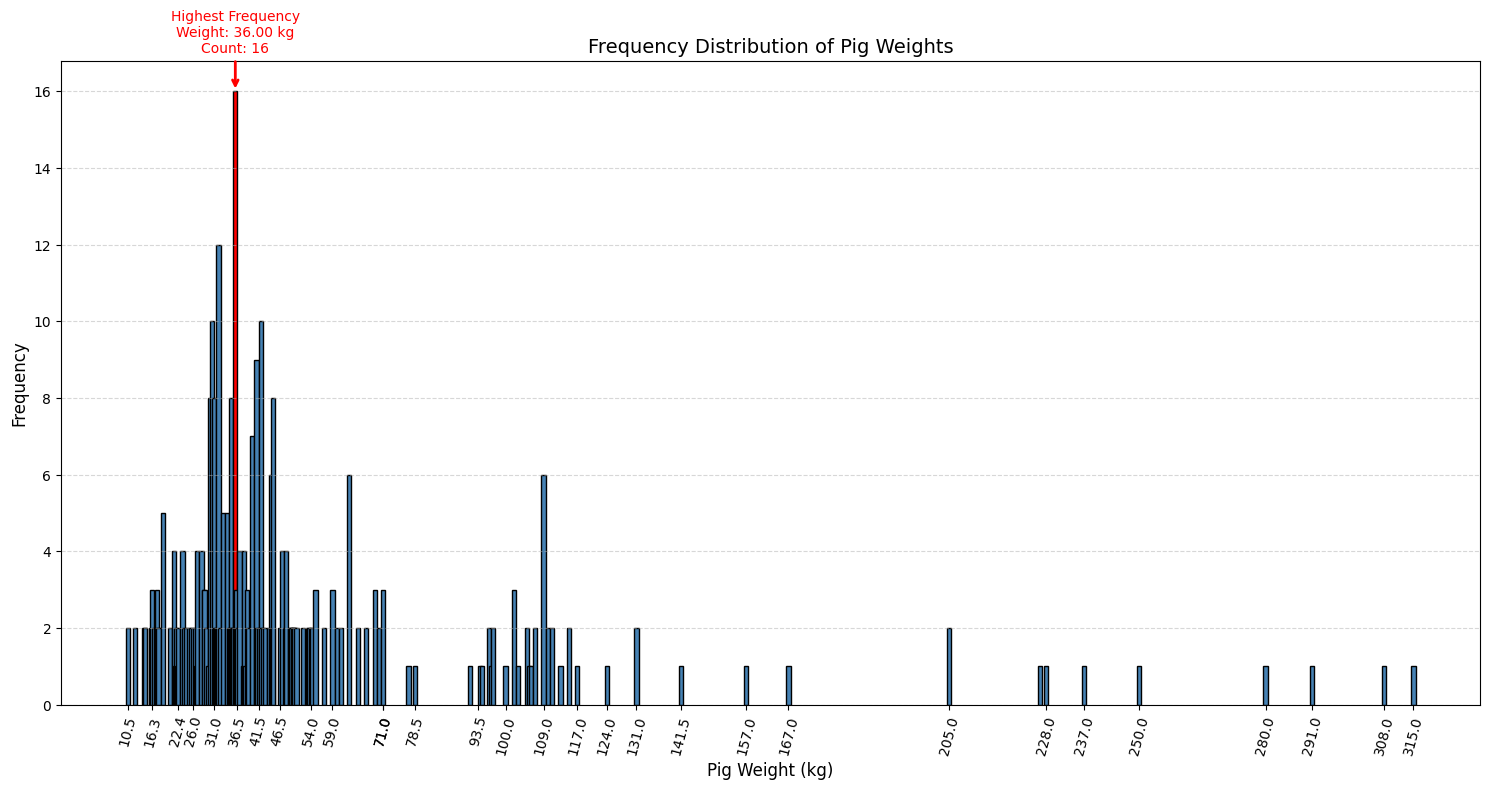

Weight with highest frequency: 36.00 kg
Frequency: 16


In [11]:
import matplotlib.pyplot as plt
from collections import Counter

counts = Counter(weights_list)

weights_sorted = sorted(counts.keys())
frequencies = [counts[w] for w in weights_sorted]

max_weight = max(counts, key=counts.get)
max_frequency = counts[max_weight]

colors = [
    "red" if w == max_weight else "steelblue"
    for w in weights_sorted
    ]

plt.figure(figsize=(15, 8))

bars = plt.bar(
    weights_sorted,
    frequencies,
    color=colors,
    edgecolor='black',
    width=1
)


plt.annotate(
    f"Highest Frequency\nWeight: {max_weight:.2f} kg\nCount: {max_frequency}",
    xy=(max_weight, max_frequency),
    xytext=(max_weight, max_frequency + 1),
    ha="center",
    color="red",
    fontsize=10,
    arrowprops=dict(
        arrowstyle="->",
        color="red",
        lw=2
    )
    )

step = max(1, len(weights_sorted) // 15)

x_ticks = [weights_sorted[i] for i in range(len(weights_sorted)-1) if weights_sorted[i+1] >= weights_sorted[i]+5] 
x_ticks.append(np.max(weights_sorted))
x_ticks.append(np.min(weights_sorted))
x_ticks.extend([16.3, 22.4, 26, 31, 36.5, 41.5, 46.5, 54, 59, 71, 93.5, 100,  109])


plt.xticks(
    x_ticks,
    rotation=75
)

# plt.xlim(
#     min(weights_sorted) - 0.2,
#     max(weights_sorted) + 0.2
# )

plt.xlabel("Pig Weight (kg)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Frequency Distribution of Pig Weights", fontsize=14)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Weight with highest frequency: {max_weight:.2f} kg")
print(f"Frequency: {max_frequency}")

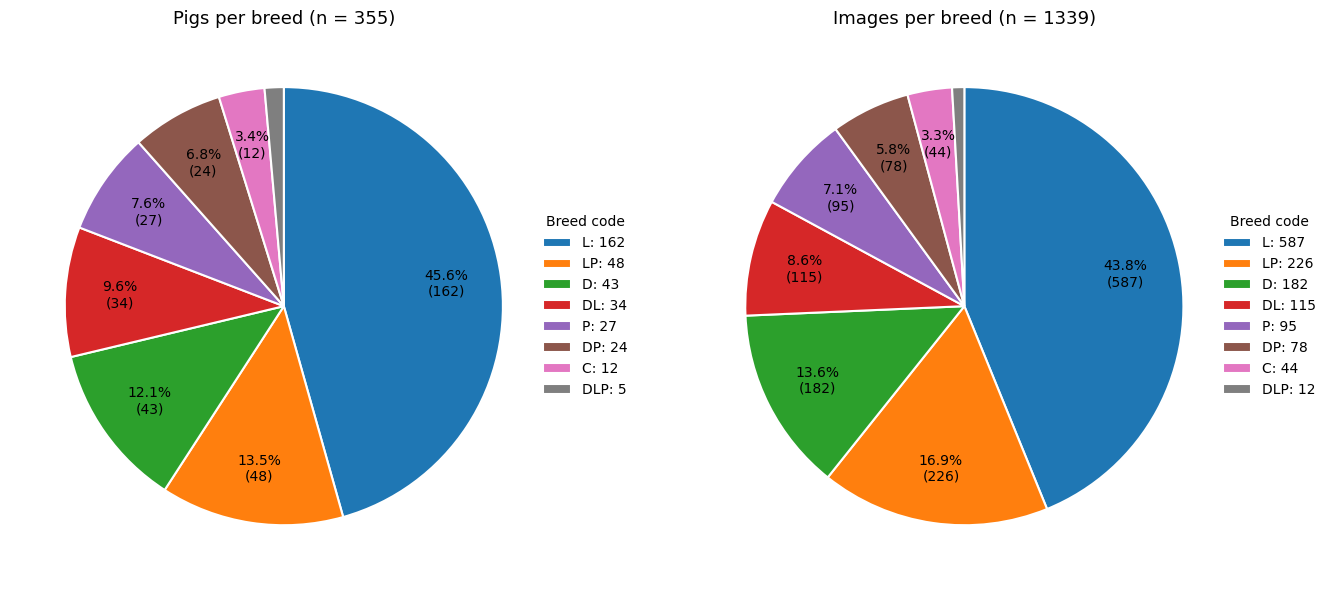

       pigs  images
breed              
L       162     587
LP       48     226
D        43     182
DL       34     115
P        27      95
DP       24      78
C        12      44
DLP       5      12

Total: 355 pigs, 1339 images
Skipped 1 folders without a breed code


In [12]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

IMG_EXTS = {".jpg", ".jpeg", ".png", ".dng"}

rows = []
skipped = []
for input_folder in [data_dir1, data_dir2, data_dir3]:
    for folder in sorted(os.listdir(input_folder)):
        subfolder = os.path.join(input_folder, folder)
        if not os.path.isdir(subfolder):
            continue
        if "_" not in folder:
            skipped.append(folder)
            continue
        code = folder.split("_")[-1]
        if not code.isalpha():
            skipped.append(folder)
            continue
        n_imgs = sum(Path(f).suffix.lower() in IMG_EXTS for f in os.listdir(subfolder))
        rows.append({"breed": code.upper(), "images": n_imgs})

df = pd.DataFrame(rows)

summary = df.groupby("breed").agg(pigs=("images", "size"), images=("images", "sum"))
summary = summary.sort_values("images", ascending=False)
for index in summary.index:
    if index =='LD':
        nbr_pigs=summary["pigs"][index]
        nbr_images=summary["images"][index]
        summary.drop(index, inplace=True)

colors = plt.cm.tab10.colors[: len(summary)]

def make_autopct(values):
    total = sum(values)
    def autopct(pct):
        count = int(round(pct * total / 100))
        return f"{pct:.1f}%\n({count})" if pct >= 3 else ""
    return autopct

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, col, title in [
    (axes[0], "pigs", "Pigs per breed"),
    (axes[1], "images", "Images per breed"),
]:
    wedges, _, _ = ax.pie(
        summary[col],
        colors=colors,
        autopct=make_autopct(summary[col]),
        startangle=90,
        counterclock=False,
        pctdistance=0.75,
        wedgeprops=dict(edgecolor="white", linewidth=1.5),
        textprops=dict(fontsize=10),
        )
    ax.set_title(f"{title} (n = {summary[col].sum()})", fontsize=13)
    ax.legend(
        wedges,
        [f"{b}: {n}" for b, n in zip(summary.index, summary[col])],
        title="Breed code",
        loc="center left",
        bbox_to_anchor=(0.95, 0.5),
        frameon=False,
        )

plt.tight_layout()
plt.savefig("breed_distribution_pie.png", dpi=200, bbox_inches="tight")
plt.show()

print(summary)
print(f"\nTotal: {summary['pigs'].sum()} pigs, {summary['images'].sum()} images")
print(f"Skipped {len(skipped)} folders without a breed code")

In [15]:
imgs=0
img_per_pig={}
for folder in os.listdir(data_dir1):
    subfolder=os.path.join(data_dir1, folder)
    for img in os.listdir(subfolder):
        imgs+=1
        if folder in img_per_pig:
            img_per_pig[folder]+=1
        else:
            img_per_pig[folder]=1
for folder in os.listdir(data_dir2):
    subfolder=os.path.join(data_dir2, folder)
    for img in os.listdir(subfolder):
        imgs+=1
        if folder in img_per_pig:
            img_per_pig[folder]+=1
        else:
            img_per_pig[folder]=1
for folder in os.listdir(data_dir3):
    subfolder=os.path.join(data_dir3, folder)
    for img in os.listdir(subfolder):
        imgs+=1
        if folder in img_per_pig:
            img_per_pig[folder]+=1
        else:
            img_per_pig[folder]=1

print(f"the dataset is made up of {imgs} images in total")


the dataset is made up of 1356 images in total


In [14]:
!pip install rawpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 14.4 MB/s  0:00:00 eta 0:00:01


In [16]:
import os
from pathlib import Path
import rawpy
from PIL import Image

def dng_to_jpg(input_path):
    folder = input_path.split("/")[5]
    img_file = input_path.split("/")[6].split(".")[0]
    input_path = Path(input_path)
    output_dir = Path(f'jpg_images/{folder}/')
    if output_dir.exists() and not output_dir.is_dir():
        os.remove(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    output_file = output_dir / f"{img_file}.jpg"
    with rawpy.imread(str(input_path)) as raw:
        rgb = raw.postprocess()
    Image.fromarray(rgb).save(output_file, "JPEG")
    return str(output_file)


In [17]:
!pip uninstall -y ultralytics
!pip cache purge
!pip install ultralytics --upgrade

Files removed: 6 (3.1 MB)
Directories removed: 16
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 6.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [ ]:
# !rm -r /kaggle/input/datasets/leonardniyitegeka/complete-dataset-pig-weight-estimation/side_views-20260723T084136Z-1-001/side_views/7640_30_lp

# 2. Segmentation with YOLO11 Model

In [18]:
import os
import gc
import cv2
import numpy as np
from pathlib import Path
import torch
from ultralytics import YOLO
from tqdm.auto import tqdm


yolo_detect = YOLO("yolo11x.pt")     
yolo_seg = YOLO("yolo11x-seg.pt")      

output_mask_folder = Path("masks")
output_crop_folder = Path("cropped_images")
output_mask_folder.mkdir(exist_ok=True)
output_crop_folder.mkdir(exist_ok=True)

MAX_SIZE = 1600
IMG_EXTS = {".jpg", ".jpeg", ".png", ".dng"}
CLEANUP_EVERY = 50          

img_count = 0
no_detection_count = 0


jobs = []
for input_folder in [data_dir1, data_dir2, data_dir3]:
    for folder in sorted(os.listdir(input_folder)):
        subfolder = os.path.join(input_folder, folder)
        if not os.path.isdir(subfolder):
            continue
        for img_file in sorted(os.listdir(subfolder)):
            if Path(img_file).suffix.lower() in IMG_EXTS:
                jobs.append((folder, subfolder, img_file))

print(f"Found {len(jobs)} images to process.")


pbar = tqdm(jobs, desc="Processing", unit="img")

for folder, subfolder, img_file in pbar:
    pbar.set_postfix(pig=folder, no_det=no_detection_count)

   
    mask_subfolder = output_mask_folder / folder
    crop_subfolder = output_crop_folder / folder
    mask_subfolder.mkdir(parents=True, exist_ok=True)
    crop_subfolder.mkdir(parents=True, exist_ok=True)

    img_path = os.path.join(subfolder, img_file)
    img_count += 1

    if img_path.lower().endswith(".dng"):          # fixed: handles .DNG too
        img_path = dng_to_jpg(img_path)

    img = cv2.imread(str(img_path))
    if img is None:
        tqdm.write(f"⚠️ Could not read: {img_path}")
        continue

    # resize guard against GPU memory blowups
    h, w = img.shape[:2]
    scale = min(MAX_SIZE / h, MAX_SIZE / w, 1.0)
    if scale < 1:
        img = cv2.resize(img, (int(w * scale), int(h * scale)))

    final_mask = np.zeros(img.shape[:2], dtype=np.uint8)
    found_pig = False

    detect_results = yolo_detect.predict(img, conf=0.3, verbose=False)

    for result in detect_results:
        boxes = result.boxes.xyxy.cpu().numpy()

        for bbox in boxes:
            x1, y1, x2, y2 = map(int, bbox[:4])
            x1, y1 = max(x1, 0), max(y1, 0)
            x2, y2 = min(x2, img.shape[1]), min(y2, img.shape[0])
            if x2 <= x1 or y2 <= y1:
                continue

            crop = img[y1:y2, x1:x2]
            # retina_masks=True returns masks at the crop's original resolution
            seg_results = yolo_seg.predict(crop, conf=0.3, retina_masks=True, verbose=False)

            for seg_res in seg_results:
                if seg_res.masks is not None:
                    for mask in seg_res.masks.data:
                        mask_array = mask.cpu().numpy().astype(np.uint8) * 255
                        if mask_array.shape != (y2 - y1, x2 - x1):
                            mask_array = cv2.resize(
                                mask_array, (x2 - x1, y2 - y1),
                                interpolation=cv2.INTER_NEAREST,
                            )
                        final_mask[y1:y2, x1:x2] = cv2.bitwise_or(
                            final_mask[y1:y2, x1:x2], mask_array
                        )
                        found_pig = True

  
    out_name = Path(img_file).stem + ".png"
    if found_pig:
        ok = cv2.imwrite(str(mask_subfolder / out_name), final_mask)
        if not ok:
            tqdm.write(f"❌ Failed to write mask for {img_path}")
        pig_only = cv2.bitwise_and(img, img, mask=final_mask)
        cv2.imwrite(str(crop_subfolder / out_name), pig_only)
    else:
        no_detection_count += 1
        tqdm.write(f"⚠️ No pig detected/segmented in: {img_path}")

    del img, final_mask
    if img_count % CLEANUP_EVERY == 0:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f"Done. Processed {img_count} images, "
      f"{no_detection_count} had no usable detection/segmentation.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Found 1356 images to process.


Processing:   0%|          | 0/1356 [00:00<?, ?img/s]

⚠️ No pig detected/segmented in: /kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/side_views-20261110T085205Z-1-001/side_views/0365847_37_lp/0365847_37_09.jpg
⚠️ No pig detected/segmented in: /kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/side_views-20261110T085205Z-1-001/side_views/0365857_36_d/0365857_36_20.jpg
⚠️ No pig detected/segmented in: /kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/side_views-20261110T085205Z-1-001/side_views/17039_67_dl/17039_67_2.jpg
⚠️ No pig detected/segmented in: /kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/side_views-20261110T085205Z-1-001/side_views/3148_109_d/IMG_6752.JPG
⚠️ No pig detected/segmented in: /kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/side_views-20261110T085205Z-1-001/side_views/376_35_dl/376_35_1.jpg
⚠️ No pig detected/segmented in: /kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/side_views-20261110T

In [36]:
!rm -r /kaggle/working/masks/0544_308_l

In [23]:
def extract_features(mask_path):
    """
    Extract geometric, shape and moment-based features from a binary
    pig mask, following the feature set described in Section 3.4 of the
    paper (area, perimeter, length/width, aspect ratio, eccentricity,
    convex-hull based compactness measures, and Hu moments).

    Returns a dict of features, or None if the mask has no usable
    foreground contour (e.g. failed segmentation).
    """
    
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return None

    # Binarize defensively in case the mask isn't strictly 0/255
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

    h_img, w_img = mask.shape[:2]
    A_img = h_img * w_img

    # --- Area-based features -------------------------------------------------
    A = int(np.sum(mask == 255))
    if A == 0:
        return None
    SR = A / A_img  # Relative projection area

    # --- Contour extraction ---------------------------------------------------
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        return None
    contour = max(contours, key=cv2.contourArea)  # largest blob = the pig

    # --- Perimeter --------------------------------------------------------
    P = cv2.arcLength(contour, True)

    # --- Length / width / aspect ratio from min-area rotated rectangle -------
    (cx_rect, cy_rect), (rw, rh), angle = cv2.minAreaRect(contour)
    BL = max(rw, rh)                                # Body Length
    BW = min(rw, rh) if min(rw, rh) > 0 else 1e-6   # Body Width (avoid /0)
    AR = rw / rh if rh > 0 else 0.0                 # Aspect ratio
    Elongation = BL / BW

    # --- Axis-aligned bounding box -> extent ----------------------------------
    x_bb, y_bb, w_bb, h_bb = cv2.boundingRect(contour)
    Extent = A / (w_bb * h_bb) if (w_bb * h_bb) > 0 else 0.0

    # --- Convex hull -> solidity ------------------------------------------
    hull = cv2.convexHull(contour)
    A_hull = cv2.contourArea(hull)
    Solidity = A / A_hull if A_hull > 0 else 0.0

    # --- Compactness / circularity --------------------------------------------
    Compactness = (P ** 2) / (4 * np.pi * A) if A > 0 else 0.0
    Circularity = (4 * np.pi * A) / (P ** 2) if P > 0 else 0.0

    # --- Eccentricity / axes from fitted ellipse (needs >= 5 contour points) ---
    if len(contour) >= 5:
        (_, _), (major_axis, minor_axis), _ = cv2.fitEllipse(contour)
        major = max(major_axis, minor_axis)
        minor = min(major_axis, minor_axis)
        E = np.sqrt(1 - (minor / major) ** 2) if major > 0 else 0.0
    else:
        major_axis, minor_axis = 0.0, 0.0
        E = 0.0

    # --- Moments: centroid + 7 Hu moments -------------------------------------
    M = cv2.moments(contour)
    if M['m00'] != 0:
        cx = M['m10'] / M['m00']
        cy = M['m01'] / M['m00']
    else:
        cx, cy = 0.0, 0.0

    hu_raw = cv2.HuMoments(M).flatten()
    # Hu moments span many orders of magnitude -> signed log transform
    hu = -np.sign(hu_raw) * np.log10(np.abs(hu_raw) + 1e-30)

    # --- Additional shape descriptors -----------------------------------------
    equivalent_diameter = np.sqrt(4 * A / np.pi)
    hull_perimeter = cv2.arcLength(hull, True)
    convexity = hull_perimeter / P if P > 0 else 0.0          # 1.0 = smooth outline, <1 = jagged/protruding (legs, ears)
    rectangularity = A / (BL * BW) if (BL * BW) > 0 else 0.0  # fill-ratio of the oriented rectangle
    perimeter_to_length = P / BL if BL > 0 else 0.0
    bbox_aspect = w_bb / h_bb if h_bb > 0 else 0.0             # axis-aligned aspect (BL/BW is orientation-corrected)
    diagonal = np.sqrt(BL ** 2 + BW ** 2)
    cx_norm = cx / w_img
    cy_norm = cy / h_img

    # --- Assemble feature dict -------------------------------------------------
    features = {
        "A": A,
        "SR": SR,
        "P": P,
        "BL": BL,
        "BW": BW,
        "aspect_ratio": AR,
        "eccentricity": E,
        "A_hull": A_hull,
        "solidity": Solidity,
        "extent": Extent,
        "compactness": Compactness,
        "circularity": Circularity,
        "elongation": Elongation,
        "cx": cx,
        "cy": cy,
        "equivalent_diameter": equivalent_diameter,
        "major_axis": major_axis,
        "minor_axis": minor_axis,
        "convexity": convexity,
        "rectangularity": rectangularity,
        "perimeter_to_length": perimeter_to_length,
        "bbox_aspect": bbox_aspect,
        "diagonal": diagonal,
        "cx_norm": cx_norm,
        "cy_norm": cy_norm,
    }

    for i in range(7):
        features[f"hu{i+1}"] = hu[i]

    return features

In [24]:
import pandas as pd

mask_dir='/kaggle/working/masks'
records = []
skipped = 0

for folder in sorted(os.listdir(mask_dir)):
    sub_folder = os.path.join(mask_dir, folder)
    if not os.path.isdir(sub_folder):
        continue

    # Folder naming schema: [pig_id]_[weight]  (see Fig. 1 in the paper)
    parts = folder.split("_")
    pig_id = parts[0]
    try:
        weight = float(parts[1])
    except (IndexError, ValueError):
        # malformed folder name (e.g. the stray "lp" entry) -> skip
        continue

    for img_file in os.listdir(sub_folder):
        mask_path = os.path.join(sub_folder, img_file)
        feats = extract_features(mask_path)
        if feats is None:
            skipped += 1
            continue
        feats["pig_id"] = pig_id
        feats["weight"] = weight
        feats["image"] = img_file
        records.append(feats)

print(f"Extracted features from {len(records)} images")
print(f"Skipped {skipped} masks with no usable contour")

features_df = pd.DataFrame(records)
features_df.to_csv("pig_features.csv", index=False)
features_df.head()


Extracted features from 1311 images
Skipped 0 masks with no usable contour


,A,SR,P,BL,BW,aspect_ratio,eccentricity,A_hull,solidity,extent,...,hu1,hu2,hu3,hu4,hu5,hu6,hu7,pig_id,weight,image
0,579899,0.402708,4943.687841,1419.060059,759.826294,1.867611,0.886485,854931.0,0.678299,0.527147,...,0.533699,1.351584,2.585198,3.208985,6.639683,4.364254,-6.125523,0036,228.0,0036_228_p_1.png
1,703270,0.488382,5543.851388,1588.510986,837.759216,1.896143,0.880505,1030218.0,0.682642,0.527185,...,0.542467,1.364905,2.544288,3.145204,6.218767,4.035633,-6.083037,0036,228.0,0036_228_p_2.png
2,697404,0.484308,5293.719365,1592.999756,820.999878,0.515380,0.888624,998024.5,0.698784,0.532261,...,0.542573,1.360191,2.556037,3.156942,6.230930,4.040308,-6.112828,0036,228.0,0036_228_p_3.png
3,708288,0.491867,5669.057457,1566.490356,831.332520,1.884313,0.872165,1019168.5,0.694967,0.541279,...,0.539830,1.347664,2.565273,3.163097,6.245484,4.062729,-6.126272,0036,228.0,0036_228_p_0.png
4,288026,0.150014,3926.068441,925.094238,611.744202,1.512224,0.777040,434804.0,0.662427,0.490075,...,0.550116,1.527518,2.498349,3.208103,-6.186213,-4.523648,-6.240909,003,23.8,IMG_6914.png


In [39]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

#feature_cols = [c for c in features_df.columns if c not in ("pig_id", "weight", "image")]
#feature_cols= ['BL', 'SR', 'BW', 'aspect_ratio', 'A_hull','solidity', "hu1",'hu2','hu3', "hu7", 'rectangularity']
feature_cols=[ 'BL', 'BW', 'aspect_ratio', 'eccentricity','A_hull', 'solidity', 'extent','compactness', 'circularity','cx', 'cy','equivalent_diameter', 'major_axis', 'minor_axis', 'convexity', 'rectangularity', 'perimeter_to_length', 'bbox_aspect', 'diagonal', 'cy_norm', 'hu1', 'hu3', 'hu4', 'hu5', 'hu6', 'hu7']
X = features_df[feature_cols]
y = features_df["weight"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Features used ({len(feature_cols)}): {feature_cols}")
print(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

model = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.005,
    depth=6,
    l2_leaf_reg=1.5,
    random_state=42,
    verbose=False,
    early_stopping_rounds=500,

)



model.fit(X_train, y_train, eval_set=(X_test, y_test))

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(f"Best iteration: {model.get_best_iteration()}")
print(f"MAE (Train): {round(mean_absolute_error(y_train, y_train_pred), 2)}")
print(f"MAE (Test): {round(mean_absolute_error(y_test, y_test_pred), 2)}")
print(f"RMSE (Train): {round(np.sqrt(mean_squared_error(y_train, y_train_pred)), 2)}")
print(f"RMSE (Test): {round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 2)}")
print(f"R2 (Train): {round(r2_score(y_train, y_train_pred), 2)}")
print(f"R2 (Test): {round(r2_score(y_test, y_test_pred), 2)}")

Features used (26): ['BL', 'BW', 'aspect_ratio', 'eccentricity', 'A_hull', 'solidity', 'extent', 'compactness', 'circularity', 'cx', 'cy', 'equivalent_diameter', 'major_axis', 'minor_axis', 'convexity', 'rectangularity', 'perimeter_to_length', 'bbox_aspect', 'diagonal', 'cy_norm', 'hu1', 'hu3', 'hu4', 'hu5', 'hu6', 'hu7']
Train set: (1048, 26), Test set: (263, 26)
Best iteration: 3560
MAE (Train): 5.34
MAE (Test): 16.38
RMSE (Train): 8.01
RMSE (Test): 32.67
R2 (Train): 0.98
R2 (Test): 0.65


In [38]:
##### #!rm -rd '/kaggle/working/masks/218_226.5_l'
#!rm -rd '/kaggle/working/masks/2842_280_p'
!rm -rd "/kaggle/working/masks/0544_308_l"
# !rm -rd /kaggle/working/masks/7653_28.5_c
#!rm -rd /kaggle/working/masks/2927_291_d
#!rm -rd /kaggle/working/masks/1706_115_lp
#!rm -rd /kaggle/working/masks/1719_124_lp
#!rm -rd /kaggle/working/masks/4548_237_c
#!rm -rd /kaggle/working/masks/765_42.1_l

#os.listdir( '/kaggle/working/masks/9122_107_d')


rm: cannot remove '/kaggle/working/masks/0544_308_l': No such file or directory


# 3. Segmentation with SAM2 model

In [42]:
"""
SAM 2 segmentation for the pig dataset, then a like-for-like comparison.

Run in your Kaggle notebook, in a cell AFTER the notebook has defined:
  data_dir1/2/3, extract_features, combined_df, and (optionally) dng_to_jpg.

    exec(open("pig_weight_improvements.py").read())   # defines the model functions
    exec(open("sam2_segmentation.py").read())

What it does, in order:
  1. YOLO finds the pig box (animal classes first), SAM 2 cuts the exact outline
     from that box (YOLO's own segmentation is NOT used any more).
  2. Keeps the main blob only, fills holes, saves to masks_sam2/<folder>/<img>.png
     (resumable: images that already have a mask are skipped).
  3. Compares with your old masks (IoU) and plots the 6 biggest disagreements.
  4. Rebuilds the features from the new masks and runs the same model comparison
     on old vs new masks, on the same images.
"""
import os
import gc
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

# ---------------- settings ----------------
SAM_WEIGHTS = "sam2.1_l.pt"       # smaller/faster: "sam2.1_b.pt"
YOLO_WEIGHTS = "yolo11x.pt"
OLD_MASK_DIR = "/kaggle/working/masks"
NEW_MASK_DIR = Path("masks_sam2")
NEW_CROP_DIR = Path("cropped_images_sam2")
MAX_SIZE = 1600                   # same resize as before, so Z/f scaling stays valid
DET_CONF = 0.10                   # low on purpose: COCO has no pig class
BOX_PAD = 0.03                    # grow the box 3% so legs/ears are not clipped
EXCLUDE = {"218_226.5_l", "023_29.6_l"}   # pigs you removed earlier
# COCO animal classes: cat dog horse sheep cow elephant bear zebra giraffe
ANIMAL_IDS = {15, 16, 17, 18, 19, 20, 21, 22, 23}
IMG_EXTS = {".jpg", ".jpeg", ".png", ".dng"}


# ---------------- pure helpers (no model needed) ----------------
def keep_main_blob(mask):
    """Largest connected component only, with holes filled. Returns 0/1 uint8."""
    mask = (mask > 0).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask)
    if n <= 1:
        return mask
    k = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    out = (lab == k).astype(np.uint8)
    cnts, _ = cv2.findContours(out, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(out)
    cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
    return filled


def mask_iou(a, b):
    a, b = a > 0, b > 0
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 0.0


def pick_box(det, shape):
    """Choose the pig box: best confidence*area among animal classes, else any non-person."""
    H, W = shape[:2]
    b = det.boxes
    if b is None or len(b) == 0:
        return None
    xyxy = b.xyxy.cpu().numpy()
    cls = b.cls.cpu().numpy().astype(int)
    conf = b.conf.cpu().numpy()
    score = conf * (xyxy[:, 2] - xyxy[:, 0]) * (xyxy[:, 3] - xyxy[:, 1])
    cand = np.where(np.isin(cls, list(ANIMAL_IDS)))[0]
    if len(cand) == 0:
        cand = np.where(cls != 0)[0]           # anything except "person"
    if len(cand) == 0:
        return None
    x1, y1, x2, y2 = xyxy[cand[np.argmax(score[cand])]]
    px, py = BOX_PAD * (x2 - x1), BOX_PAD * (y2 - y1)
    return [float(max(0, x1 - px)), float(max(0, y1 - py)),
            float(min(W, x2 + px)), float(min(H, y2 + py))]


def load_resized(path):
    if path.lower().endswith(".dng"):
        path = dng_to_jpg(path)               # your notebook's converter
    img = cv2.imread(str(path))
    if img is None:
        return None
    h, w = img.shape[:2]
    s = min(MAX_SIZE / h, MAX_SIZE / w, 1.0)
    return cv2.resize(img, (int(w * s), int(h * s))) if s < 1 else img


# ---------------- 1+2. segment everything ----------------
def segment_all():
    import torch
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)

    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    print(f"{len(jobs)} images to segment with SAM 2 ({SAM_WEIGHTS})")

    failed = []
    for i, (folder, path) in enumerate(tqdm(jobs, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        if out_m.exists():
            continue                                     # resume
        img = load_resized(path)
        if img is None:
            failed.append((path, "unreadable"))
            continue
        det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
        box = pick_box(det, img.shape)
        if box is None:
            failed.append((path, "no box"))
            continue
        res = sam(img, bboxes=box, verbose=False)[0]
        if res.masks is None or len(res.masks.data) == 0:
            failed.append((path, "no mask"))
            continue
        m = res.masks.data[0].cpu().numpy()
        if m.shape != img.shape[:2]:
            m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                           interpolation=cv2.INTER_NEAREST)
        m = keep_main_blob(m)
        frac = m.mean()
        if frac < 0.01 or frac > 0.95:
            failed.append((path, f"implausible area {frac:.3f}"))
            continue
        (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
        (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out_m), m * 255)
        cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                    cv2.bitwise_and(img, img, mask=m))
        if i % 50 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    print(f"Done. {len(failed)} images failed.")
    for p, why in failed[:15]:
        print("  ", why, "->", p)
    return failed


# ---------------- 3. old vs new masks ----------------
def compare_masks(n_show=6):
    import matplotlib.pyplot as plt
    rows = []
    for folder in sorted(os.listdir(NEW_MASK_DIR)):
        for f in os.listdir(NEW_MASK_DIR / folder):
            old_p = Path(OLD_MASK_DIR) / folder / f
            if not old_p.exists():
                continue
            new = cv2.imread(str(NEW_MASK_DIR / folder / f), 0)
            old = cv2.imread(str(old_p), 0)
            if old.shape != new.shape:
                old = cv2.resize(old, (new.shape[1], new.shape[0]), interpolation=cv2.INTER_NEAREST)
            rows.append({"folder": folder, "file": f, "iou": mask_iou(old, new),
                         "old_frac": (old > 0).mean(), "new_frac": (new > 0).mean()})
    r = pd.DataFrame(rows).sort_values("iou")
    print(f"IoU old vs SAM 2: median {r['iou'].median():.3f} | "
          f"{(r['iou'] < 0.8).sum()} of {len(r)} images below 0.8")
    print("Lowest agreement:\n", r.head(10).round(3).to_string(index=False))

    # NOTE: judge visually which mask is right. Low IoU means one of them is wrong.
    fig, ax = plt.subplots(n_show, 3, figsize=(12, 3.2 * n_show))
    for k, (_, row) in enumerate(r.head(n_show).iterrows()):
        stem = Path(row["file"]).stem
        root = next((d for d in [data_dir1, data_dir2, data_dir3]
                     if os.path.isdir(os.path.join(d, row["folder"]))), None)
        src = next((os.path.join(root, row["folder"], x) for x in os.listdir(os.path.join(root, row["folder"]))
                    if Path(x).stem == stem), None) if root else None
        img = load_resized(src) if src else None
        old = cv2.imread(str(Path(OLD_MASK_DIR) / row["folder"] / row["file"]), 0)
        new = cv2.imread(str(NEW_MASK_DIR / row["folder"] / row["file"]), 0)
        for a, im, title in zip(ax[k], [img, old, new],
                                [f"{row['folder']} (IoU {row['iou']:.2f})", "old (YOLO seg)", "new (SAM 2)"]):
            if im is not None:
                a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap="gray")
            a.set_title(title, fontsize=9)
            a.axis("off")
    plt.tight_layout()
    plt.show()
    return r


# ---------------- 4. rebuild features and compare models ----------------
def rebuild_and_compare():
    recs = []
    for folder in sorted(os.listdir(NEW_MASK_DIR)):
        parts = folder.split("_")
        try:
            weight = float(parts[1])
        except (IndexError, ValueError):
            continue
        for f in os.listdir(NEW_MASK_DIR / folder):
            feats = extract_features(str(NEW_MASK_DIR / folder / f))   # your notebook's function
            if feats is None:
                continue
            feats.update({"pig_id": parts[0], "weight": weight, "filename": f})
            recs.append(feats)
    feats_new = pd.DataFrame(recs)
    feats_new.to_csv("features_sam2.csv", index=False)

    dep = depth_df.copy() if "depth_df" in globals() else pd.read_csv(
        "/kaggle/input/datasets/leonardniyitegeka/data-extracted/depth.csv")
    dep["filename"] = dep["filename"].str.replace(r"\.(jpg|jpeg|png)$", ".png", regex=True, case=False)
    comb_new = feats_new.merge(dep, on="filename")
    comb_new = add_metric_from_existing(comb_new)

    comb_old = combined_df if "BL_m" in combined_df else add_metric_from_existing(combined_df)

    # same images, same order -> same train/test split for both runs
    common = sorted(set(comb_old["filename"]) & set(comb_new["filename"]))
    old = comb_old[comb_old["filename"].isin(common)].sort_values("filename").reset_index(drop=True)
    new = comb_new[comb_new["filename"].isin(common)].sort_values("filename").reset_index(drop=True)
    print(f"\nComparing on {len(common)} images present in both mask sets\n")

    print("=== OLD masks (YOLO seg) ===")
    t_old, _, _ = run_comparison(old)
    print("\n=== NEW masks (SAM 2) ===")
    t_new, _, _ = run_comparison(new)
    return comb_new, t_old, t_new




In [44]:
import gc, torch

def build_jobs():
    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    return jobs


def segment_part(part, n_parts=4):
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    jobs = build_jobs()
    chunks = np.array_split(np.arange(len(jobs)), n_parts)
    mine = [jobs[i] for i in chunks[part - 1]]
    todo = [(f, p) for f, p in mine
            if not (NEW_MASK_DIR / f / f"{Path(p).stem}.png").exists()]
    print(f"Part {part}/{n_parts}: {len(mine)} images, {len(todo)} still to do "
          f"(total dataset {len(jobs)})")
    if not todo:
        return []

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)
    failed = []

    for n, (folder, path) in enumerate(tqdm(todo, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        try:
            img = load_resized(path)
            if img is None:
                failed.append((path, "unreadable")); continue
            det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
            box = pick_box(det, img.shape)
            if box is None:
                failed.append((path, "no box")); continue
            res = sam(img, bboxes=box, verbose=False)[0]
            if res.masks is None or len(res.masks.data) == 0:
                failed.append((path, "no mask")); continue
            m = res.masks.data[0].cpu().numpy()
            if m.shape != img.shape[:2]:
                m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                               interpolation=cv2.INTER_NEAREST)
            m = keep_main_blob(m)
            frac = m.mean()
            if frac < 0.01 or frac > 0.95:
                failed.append((path, f"implausible area {frac:.3f}")); continue
            (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
            (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out_m), m * 255)
            cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                        cv2.bitwise_and(img, img, mask=m))
        except Exception as e:
            failed.append((path, f"error: {type(e).__name__}: {e}"))
        if n % 25 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    del yolo, sam
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    pd.DataFrame(failed, columns=["path", "reason"]).to_csv(f"failed_part{part}.csv", index=False)
    print(f"Part {part} done. {len(failed)} failed (saved to failed_part{part}.csv)")
    for p, why in failed[:10]:
        print("  ", why,   "->", p)
    return failed


failed1 = segment_part(1)

Part 1/4: 334 images, 0 still to do (total dataset 1335)


In [45]:
import gc, torch

def build_jobs():
    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    return jobs


def segment_part(part, n_parts=4):
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    jobs = build_jobs()
    chunks = np.array_split(np.arange(len(jobs)), n_parts)
    mine = [jobs[i] for i in chunks[part - 1]]
    todo = [(f, p) for f, p in mine
            if not (NEW_MASK_DIR / f / f"{Path(p).stem}.png").exists()]
    print(f"Part {part}/{n_parts}: {len(mine)} images, {len(todo)} still to do "
          f"(total dataset {len(jobs)})")
    if not todo:
        return []

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)
    failed = []

    for n, (folder, path) in enumerate(tqdm(todo, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        try:
            img = load_resized(path)
            if img is None:
                failed.append((path, "unreadable")); continue
            det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
            box = pick_box(det, img.shape)
            if box is None:
                failed.append((path, "no box")); continue
            res = sam(img, bboxes=box, verbose=False)[0]
            if res.masks is None or len(res.masks.data) == 0:
                failed.append((path, "no mask")); continue
            m = res.masks.data[0].cpu().numpy()
            if m.shape != img.shape[:2]:
                m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                               interpolation=cv2.INTER_NEAREST)
            m = keep_main_blob(m)
            frac = m.mean()
            if frac < 0.01 or frac > 0.95:
                failed.append((path, f"implausible area {frac:.3f}")); continue
            (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
            (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out_m), m * 255)
            cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                        cv2.bitwise_and(img, img, mask=m))
        except Exception as e:
            failed.append((path, f"error: {type(e).__name__}: {e}"))
        if n % 25 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    del yolo, sam
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    pd.DataFrame(failed, columns=["path", "reason"]).to_csv(f"failed_part{part}.csv", index=False)
    print(f"Part {part} done. {len(failed)} failed (saved to failed_part{part}.csv)")
    for p, why in failed[:10]:
        print("  ", why, "->", p)
    return failed


failed1 = segment_part(2)

Part 2/4: 334 images, 334 still to do (total dataset 1335)


  0%|          | 0/334 [00:00<?, ?img/s]

Part 2 done. 0 failed (saved to failed_part2.csv)


In [46]:
import gc, torch

def build_jobs():
    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    return jobs


def segment_part(part, n_parts=4):
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    jobs = build_jobs()
    chunks = np.array_split(np.arange(len(jobs)), n_parts)
    mine = [jobs[i] for i in chunks[part - 1]]
    todo = [(f, p) for f, p in mine
            if not (NEW_MASK_DIR / f / f"{Path(p).stem}.png").exists()]
    print(f"Part {part}/{n_parts}: {len(mine)} images, {len(todo)} still to do "
          f"(total dataset {len(jobs)})")
    if not todo:
        return []

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)
    failed = []

    for n, (folder, path) in enumerate(tqdm(todo, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        try:
            img = load_resized(path)
            if img is None:
                failed.append((path, "unreadable")); continue
            det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
            box = pick_box(det, img.shape)
            if box is None:
                failed.append((path, "no box")); continue
            res = sam(img, bboxes=box, verbose=False)[0]
            if res.masks is None or len(res.masks.data) == 0:
                failed.append((path, "no mask")); continue
            m = res.masks.data[0].cpu().numpy()
            if m.shape != img.shape[:2]:
                m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                               interpolation=cv2.INTER_NEAREST)
            m = keep_main_blob(m)
            frac = m.mean()
            if frac < 0.01 or frac > 0.95:
                failed.append((path, f"implausible area {frac:.3f}")); continue
            (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
            (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out_m), m * 255)
            cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                        cv2.bitwise_and(img, img, mask=m))
        except Exception as e:
            failed.append((path, f"error: {type(e).__name__}: {e}"))
        if n % 25 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    del yolo, sam
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    pd.DataFrame(failed, columns=["path", "reason"]).to_csv(f"failed_part{part}.csv", index=False)
    print(f"Part {part} done. {len(failed)} failed (saved to failed_part{part}.csv)")
    for p, why in failed[:10]:
        print("  ", why, "->", p)
    return failed


failed1 = segment_part(3)

Part 3/4: 334 images, 334 still to do (total dataset 1335)


  0%|          | 0/334 [00:00<?, ?img/s]

Part 3 done. 0 failed (saved to failed_part3.csv)


In [47]:
import gc, torch

def build_jobs():
    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    return jobs


def segment_part(part, n_parts=4):
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    jobs = build_jobs()
    chunks = np.array_split(np.arange(len(jobs)), n_parts)
    mine = [jobs[i] for i in chunks[part - 1]]
    todo = [(f, p) for f, p in mine
            if not (NEW_MASK_DIR / f / f"{Path(p).stem}.png").exists()]
    print(f"Part {part}/{n_parts}: {len(mine)} images, {len(todo)} still to do "
          f"(total dataset {len(jobs)})")
    if not todo:
        return []

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)
    failed = []

    for n, (folder, path) in enumerate(tqdm(todo, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        try:
            img = load_resized(path)
            if img is None:
                failed.append((path, "unreadable")); continue
            det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
            box = pick_box(det, img.shape)
            if box is None:
                failed.append((path, "no box")); continue
            res = sam(img, bboxes=box, verbose=False)[0]
            if res.masks is None or len(res.masks.data) == 0:
                failed.append((path, "no mask")); continue
            m = res.masks.data[0].cpu().numpy()
            if m.shape != img.shape[:2]:
                m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                               interpolation=cv2.INTER_NEAREST)
            m = keep_main_blob(m)
            frac = m.mean()
            if frac < 0.01 or frac > 0.95:
                failed.append((path, f"implausible area {frac:.3f}")); continue
            (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
            (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out_m), m * 255)
            cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                        cv2.bitwise_and(img, img, mask=m))
        except Exception as e:
            failed.append((path, f"error: {type(e).__name__}: {e}"))
        if n % 25 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    del yolo, sam
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    pd.DataFrame(failed, columns=["path", "reason"]).to_csv(f"failed_part{part}.csv", index=False)
    print(f"Part {part} done. {len(failed)} failed (saved to failed_part{part}.csv)")
    for p, why in failed[:10]:
        print("  ", why, "->", p)
    return failed


failed1 = segment_part(4)

Part 4/4: 333 images, 333 still to do (total dataset 1335)


  0%|          | 0/333 [00:00<?, ?img/s]

Part 4 done. 0 failed (saved to failed_part4.csv)


In [51]:
!rm -r /kaggle/working/masks_sam2/0544_308_l

rm: cannot remove '/kaggle/working/masks_sam2/0544_308_l': No such file or directory


In [52]:
import pandas as pd

mask_dir='/kaggle/working/masks_sam2'
records = []
skipped = 0

for folder in sorted(os.listdir(mask_dir)):
    sub_folder = os.path.join(mask_dir, folder)
    if not os.path.isdir(sub_folder):
        continue

    # Folder naming schema: [pig_id]_[weight]  (see Fig. 1 in the paper)
    parts = folder.split("_")
    pig_id = parts[0]
    try:
        weight = float(parts[1])
    except (IndexError, ValueError):
        # malformed folder name (e.g. the stray "lp" entry) -> skip
        continue

    for img_file in os.listdir(sub_folder):
        mask_path = os.path.join(sub_folder, img_file)
        feats = extract_features(mask_path)
        if feats is None:
            skipped += 1
            continue
        feats["pig_id"] = pig_id
        feats["weight"] = weight
        feats["image"] = img_file
        records.append(feats)

print(f"Extracted features from {len(records)} images")
print(f"Skipped {skipped} masks with no usable contour")

feat_df = pd.DataFrame(records)
feat_df.to_csv("pig_features.csv", index=False)
feat_df.head()


Extracted features from 1322 images
Skipped 0 masks with no usable contour


,A,SR,P,BL,BW,aspect_ratio,eccentricity,A_hull,solidity,extent,...,hu1,hu2,hu3,hu4,hu5,hu6,hu7,pig_id,weight,image
0,576277,0.400192,5292.547794,1430.949341,774.908569,1.846604,0.864110,886155.0,0.650312,0.508982,...,0.523628,1.327382,2.465607,3.084464,6.329181,4.269965,-5.886024,0036,228.0,0036_228_p_1.png
1,700280,0.486306,5719.692008,1570.638428,857.859985,1.830880,0.864640,1042412.0,0.671788,0.510718,...,0.534674,1.346329,2.451148,3.034574,5.983840,3.935687,-5.883540,0036,228.0,0036_228_p_2.png
2,699432,0.485717,5699.466618,1586.621826,846.640808,1.874020,0.873852,1034741.5,0.675949,0.515900,...,0.534248,1.340128,2.466794,3.049529,6.009155,3.953179,-5.916969,0036,228.0,0036_228_p_3.png
3,694875,0.482552,5639.366108,1555.257935,852.397705,1.824568,0.861396,1027268.0,0.676430,0.515092,...,0.532459,1.336071,2.462718,3.061021,6.050375,3.978889,-5.916695,0036,228.0,0036_228_p_0.png
4,281205,0.146461,4054.820745,918.670776,612.635864,1.499538,0.777405,433109.5,0.649270,0.476634,...,0.540471,1.484865,2.456538,3.160428,-6.122028,-4.491635,-6.116857,003,23.8,IMG_6914.png


In [93]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

#feature_cols = [c for c in features_df.columns if c not in ("pig_id", "weight", "image")]
#feature_cols= ['BL', 'SR', 'BW', 'aspect_ratio', 'A_hull','solidity', "hu1",'hu2','hu3', "hu7", 'rectangularity']
feature_cols=['A', 'SR', 'P', 'BL', 'BW', 'aspect_ratio', 'eccentricity', 'A_hull', 'solidity', 'compactness', 'elongation', 'cx', 'cy', 'equivalent_diameter', 'major_axis', 'minor_axis', 'convexity', 'rectangularity', 'perimeter_to_length', 'bbox_aspect', 'diagonal', 'cx_norm', 'cy_norm', 'hu1', 'hu2', 'hu3', 'hu4', 'hu5','hu6', 'hu7']
X = feat_df[feature_cols]
y = feat_df["weight"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Features used ({len(feature_cols)}): {feature_cols}")
print(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

model = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=0.5,
    random_state=42,
    verbose=False,
    early_stopping_rounds=500,
)

model.fit(X_train, y_train, eval_set=(X_test, y_test))

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(f"Best iteration: {model.get_best_iteration()}")
print(f"MAE (Train): {round(mean_absolute_error(y_train, y_train_pred), 2)}")
print(f"MAE (Test): {round(mean_absolute_error(y_test, y_test_pred), 2)}")
print(f"RMSE (Train): {round(np.sqrt(mean_squared_error(y_train, y_train_pred)), 2)}")
print(f"RMSE (Test): {round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 2)}")
print(f"R2 (Train): {round(r2_score(y_train, y_train_pred), 2)}")
print(f"R2 (Test): {round(r2_score(y_test, y_test_pred), 2)}")

Features used (30): ['A', 'SR', 'P', 'BL', 'BW', 'aspect_ratio', 'eccentricity', 'A_hull', 'solidity', 'compactness', 'elongation', 'cx', 'cy', 'equivalent_diameter', 'major_axis', 'minor_axis', 'convexity', 'rectangularity', 'perimeter_to_length', 'bbox_aspect', 'diagonal', 'cx_norm', 'cy_norm', 'hu1', 'hu2', 'hu3', 'hu4', 'hu5', 'hu6', 'hu7']
Train set: (1057, 30), Test set: (265, 30)
Best iteration: 4784
MAE (Train): 0.14
MAE (Test): 9.38
RMSE (Train): 0.65
RMSE (Test): 16.12
R2 (Train): 1.0
R2 (Test): 0.83


# 3. Depth(distance) estimation

In [94]:
!git clone https://github.com/apple/ml-depth-pro.git
%cd ml-depth-pro 

Cloning into 'ml-depth-pro'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 50 (delta 10), reused 2 (delta 2), pack-reused 21 (from 1)
Receiving objects: 100% (50/50), 2.50 MiB | 24.65 MiB/s, done.
Resolving deltas: 100% (10/10), done.
/kaggle/working/ml-depth-pro


In [95]:
!pip install -e .

Obtaining file:///kaggle/working/ml-depth-pro
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 28.6 MB/s  0:00:00eta 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 57.6 MB/s  0:00:00
  Building editable for depth_pro (pyproject.toml) ... done
  Created wheel for depth_pro: filename=depth_pro-0.1-0.editable-py3-none-any.whl size=4843 sha256=6866eae5c61b2208a639984714a0a8dbb259b05b22b09afd5d6928daac59688f
  Stored in directory: /tmp/pip-eph

In [98]:
!bash get_pretrained_models.sh

--2026-11-10 14:46:28--  https://ml-site.cdn-apple.com/models/depth-pro/depth_pro.pt
Resolving ml-site.cdn-apple.com (ml-site.cdn-apple.com)... 17.253.7.148, 17.253.7.151, 2620:149:a16:f000::152, ...
Connecting to ml-site.cdn-apple.com (ml-site.cdn-apple.com)|17.253.7.148|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1904446787 (1.8G) [binary/octet-stream]
Saving to: ‘checkpoints/depth_pro.pt.2’

depth_pro.pt.2      100%[===================>]   1.77G   350MB/s    in 5.1s    

2026-11-10 14:46:33 (353 MB/s) - ‘checkpoints/depth_pro.pt.2’ saved [1904446787/1904446787]



In [ ]:
ls

In [99]:
cd src

/kaggle/working/ml-depth-pro/src


In [ ]:
cd ..

In [100]:
%mv "src/depth_pro" .


mv: cannot stat 'src/depth_pro': No such file or directory


In [ ]:
!pip install --force-reinstall "numpy<2"

In [103]:
cd ..

/kaggle/working/ml-depth-pro


In [105]:
from PIL import Image
import depth_pro

# Load model and preprocessing transform
model, transform = depth_pro.create_model_and_transforms()
model.eval()

# Load and preprocess an image
image, _, f_px = depth_pro.load_rgb("/kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/Detailed data-20261110T084851Z-1-001/Detailed data/127_70.1_l/PXL_20261109_143445581.jpg")
image = transform(image)

# Run inference
prediction = model.infer(image, f_px=f_px)
depth = prediction["depth"]              # Depth in meters
focallength_px = prediction["focallength_px"]

In [106]:
depth_np = depth.squeeze().cpu().numpy()   # meters

In [107]:
h, w = depth_np.shape
print("center pixel:", round(depth_np[h // 2, w // 2],2), "m")
print("median of center patch:", np.median(depth_np[h//2-20:h//2+20, w//2-20:w//2+20]), "m")

center pixel: 0.94 m
median of center patch: 0.9442675 m


In [ ]:
pwd

In [108]:
import os
import glob
import numpy as np
import pandas as pd
import torch
import depth_pro
from tqdm import tqdm


DATA_DIRS = {"001": data_dir1, "002": data_dir2, "003": data_dir3}

PATCH = 10           
SAVE_EVERY = 200      
OUT_CSV = "/kaggle/working/center_distances_all.csv"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, transform = depth_pro.create_model_and_transforms(device=device)
model.eval()

exts = ("*.jpg", "*.jpeg", "*.png")
paths = []
for label, d in DATA_DIRS.items():
    found = []
    for ext in exts:
        found += glob.glob(os.path.join(d, "**", ext), recursive=True)
    print(f"{label}: {len(found)} images")
    paths += [(label, p) for p in sorted(found)]
print(f"Total: {len(paths)} images")

rows = []
for i, (label, p) in enumerate(tqdm(paths), 1):
    row = {
        "data_dir": label,
        "folder": os.path.basename(os.path.dirname(p)),
        "filename": os.path.basename(p),
        "distance_center_m": np.nan,
        "distance_center_patch_median_m": np.nan,
        "focal_length_px": np.nan,
        "path": p,
    }
    try:
        image, _, f_px = depth_pro.load_rgb(p)
        image = transform(image).to(device)
        with torch.no_grad():
            pred = model.infer(image, f_px=f_px)

        depth_np = pred["depth"].squeeze().cpu().numpy()
        h, w = depth_np.shape
        cy, cx = h // 2, w // 2

        row["distance_center_m"] = round(float(depth_np[cy, cx]), 3)
        row["distance_center_patch_median_m"] = round(float(np.median(
            depth_np[max(cy - PATCH, 0):cy + PATCH + 1,
                     max(cx - PATCH, 0):cx + PATCH + 1])), 3)
        row["focal_length_px"] = float(pred["focallength_px"])
    except Exception as e:
        print(f"Failed on {p}: {e}")
    rows.append(row)

    if i % SAVE_EVERY == 0:
        pd.DataFrame(rows).to_csv(OUT_CSV, index=False)

df = pd.DataFrame(rows)
df.to_csv(OUT_CSV, index=False)

print(df.groupby("data_dir")["distance_center_m"].describe())
df.head()

001: 443 images
002: 467 images
003: 207 images
Total: 1117 images


100%|██████████| 1117/1117 [2:00:56<00:00,  6.50s/it] 

          count      mean       std    min     25%    50%     75%    max
data_dir                                                                
001       443.0  1.394321  0.410621  0.579  1.0360  1.400  1.6815  2.698
002       467.0  1.334683  0.413246  0.592  0.9770  1.316  1.6075  2.464
003       207.0  1.010715  0.259131  0.069  0.8685  0.974  1.1580  1.970


,data_dir,folder,filename,distance_center_m,distance_center_patch_median_m,focal_length_px,path
0,001,004_24.3_l,004_24.3_l_0.jpg,1.452,1.453,2566.101383,/kaggle/input/datasets/leonard250/complete-pig...
1,001,004_24.3_l,004_24.3_l_3.jpg,1.289,1.289,2566.101383,/kaggle/input/datasets/leonard250/complete-pig...
2,001,004_24.3_l,004_24.3_l_4.jpg,1.000,1.001,2566.101383,/kaggle/input/datasets/leonard250/complete-pig...
3,001,005_41.2_l,005_41.2_l_0.jpg,1.044,1.044,2566.101383,/kaggle/input/datasets/leonard250/complete-pig...
4,001,005_41.2_l,005_41.2_l_2.jpg,1.030,1.030,2566.101383,/kaggle/input/datasets/leonard250/complete-pig...


In [ ]:
import gc, torch

def build_jobs():
    
    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    return jobs


def segment_part(part, n_parts=4):
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    jobs = build_jobs()
    chunks = np.array_split(np.arange(len(jobs)), n_parts)
    mine = [jobs[i] for i in chunks[part - 1]]
    todo = [(f, p) for f, p in mine
            if not (NEW_MASK_DIR / f / f"{Path(p).stem}.png").exists()]
    print(f"Part {part}/{n_parts}: {len(mine)} images, {len(todo)} still to do "
          f"(total dataset {len(jobs)})")
    if not todo:
        return []

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)
    failed = []

    for n, (folder, path) in enumerate(tqdm(todo, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        try:
            img = load_resized(path)
            if img is None:
                failed.append((path, "unreadable")); continue
            det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
            box = pick_box(det, img.shape)
            if box is None:
                failed.append((path, "no box")); continue
            res = sam(img, bboxes=box, verbose=False)[0]
            if res.masks is None or len(res.masks.data) == 0:
                failed.append((path, "no mask")); continue
            m = res.masks.data[0].cpu().numpy()
            if m.shape != img.shape[:2]:
                m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                               interpolation=cv2.INTER_NEAREST)
            m = keep_main_blob(m)
            frac = m.mean()
            if frac < 0.01 or frac > 0.95:
                failed.append((path, f"implausible area {frac:.3f}")); continue
            (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
            (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out_m), m * 255)
            cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                        cv2.bitwise_and(img, img, mask=m))
        except Exception as e:
            failed.append((path, f"error: {type(e).__name__}: {e}"))
        if n % 25 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    del yolo, sam
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    pd.DataFrame(failed, columns=["path", "reason"]).to_csv(f"failed_part{part}.csv", index=False)
    print(f"Part {part} done. {len(failed)} failed (saved to failed_part{part}.csv)")
    for p, why in failed[:10]:
        print("  ", why, "->", p)
    return failed


failed1 = segment_part(3)

In [ ]:
import gc, torch

def build_jobs():
    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    return jobs


def segment_part(part, n_parts=4):
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    jobs = build_jobs()
    chunks = np.array_split(np.arange(len(jobs)), n_parts)
    mine = [jobs[i] for i in chunks[part - 1]]
    todo = [(f, p) for f, p in mine
            if not (NEW_MASK_DIR / f / f"{Path(p).stem}.png").exists()]
    print(f"Part {part}/{n_parts}: {len(mine)} images, {len(todo)} still to do "
          f"(total dataset {len(jobs)})")
    if not todo:
        return []

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)
    failed = []

    for n, (folder, path) in enumerate(tqdm(todo, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        try:
            img = load_resized(path)
            if img is None:
                failed.append((path, "unreadable")); continue
            det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
            box = pick_box(det, img.shape)
            if box is None:
                failed.append((path, "no box")); continue
            res = sam(img, bboxes=box, verbose=False)[0]
            if res.masks is None or len(res.masks.data) == 0:
                failed.append((path, "no mask")); continue
            m = res.masks.data[0].cpu().numpy()
            if m.shape != img.shape[:2]:
                m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                               interpolation=cv2.INTER_NEAREST)
            m = keep_main_blob(m)
            frac = m.mean()
            if frac < 0.01 or frac > 0.95:
                failed.append((path, f"implausible area {frac:.3f}")); continue
            (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
            (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out_m), m * 255)
            cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                        cv2.bitwise_and(img, img, mask=m))
        except Exception as e:
            failed.append((path, f"error: {type(e).__name__}: {e}"))
        if n % 25 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    del yolo, sam
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    pd.DataFrame(failed, columns=["path", "reason"]).to_csv(f"failed_part{part}.csv", index=False)
    print(f"Part {part} done. {len(failed)} failed (saved to failed_part{part}.csv)")
    for p, why in failed[:10]:
        print("  ", why, "->", p)
    return failed


failed1 = segment_part(4)

In [ ]:
"""
SAM 2 segmentation for the pig dataset, then a like-for-like comparison.

Run in your Kaggle notebook, in a cell AFTER the notebook has defined:
  data_dir1/2/3, extract_features, combined_df, and (optionally) dng_to_jpg.

    exec(open("pig_weight_improvements.py").read())   # defines the model functions
    exec(open("sam2_segmentation.py").read())

What it does, in order:
  1. YOLO finds the pig box (animal classes first), SAM 2 cuts the exact outline
     from that box (YOLO's own segmentation is NOT used any more).
  2. Keeps the main blob only, fills holes, saves to masks_sam2/<folder>/<img>.png
     (resumable: images that already have a mask are skipped).
  3. Compares with your old masks (IoU) and plots the 6 biggest disagreements.
  4. Rebuilds the features from the new masks and runs the same model comparison
     on old vs new masks, on the same images.
"""
import os
import gc
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

# ---------------- settings ----------------
SAM_WEIGHTS = "sam2.1_l.pt"       # smaller/faster: "sam2.1_b.pt"
YOLO_WEIGHTS = "yolo11x.pt"
OLD_MASK_DIR = "/kaggle/working/masks"
NEW_MASK_DIR = Path("masks_sam2")
NEW_CROP_DIR = Path("cropped_images_sam2")
MAX_SIZE = 1600                   # same resize as before, so Z/f scaling stays valid
DET_CONF = 0.10                   # low on purpose: COCO has no pig class
BOX_PAD = 0.03                    # grow the box 3% so legs/ears are not clipped
EXCLUDE = {"218_226.5_l", "023_29.6_l"}   # pigs you removed earlier
# COCO animal classes: cat dog horse sheep cow elephant bear zebra giraffe
ANIMAL_IDS = {15, 16, 17, 18, 19, 20, 21, 22, 23}
IMG_EXTS = {".jpg", ".jpeg", ".png", ".dng"}


# ---------------- pure helpers (no model needed) ----------------
def keep_main_blob(mask):
    """Largest connected component only, with holes filled. Returns 0/1 uint8."""
    mask = (mask > 0).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask)
    if n <= 1:
        return mask
    k = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    out = (lab == k).astype(np.uint8)
    cnts, _ = cv2.findContours(out, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(out)
    cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
    return filled


def mask_iou(a, b):
    a, b = a > 0, b > 0
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 0.0


def pick_box(det, shape):
    """Choose the pig box: best confidence*area among animal classes, else any non-person."""
    H, W = shape[:2]
    b = det.boxes
    if b is None or len(b) == 0:
        return None
    xyxy = b.xyxy.cpu().numpy()
    cls = b.cls.cpu().numpy().astype(int)
    conf = b.conf.cpu().numpy()
    score = conf * (xyxy[:, 2] - xyxy[:, 0]) * (xyxy[:, 3] - xyxy[:, 1])
    cand = np.where(np.isin(cls, list(ANIMAL_IDS)))[0]
    if len(cand) == 0:
        cand = np.where(cls != 0)[0]           # anything except "person"
    if len(cand) == 0:
        return None
    x1, y1, x2, y2 = xyxy[cand[np.argmax(score[cand])]]
    px, py = BOX_PAD * (x2 - x1), BOX_PAD * (y2 - y1)
    return [float(max(0, x1 - px)), float(max(0, y1 - py)),
            float(min(W, x2 + px)), float(min(H, y2 + py))]


def load_resized(path):
    if path.lower().endswith(".dng"):
        path = dng_to_jpg(path)               # your notebook's converter
    img = cv2.imread(str(path))
    if img is None:
        return None
    h, w = img.shape[:2]
    s = min(MAX_SIZE / h, MAX_SIZE / w, 1.0)
    return cv2.resize(img, (int(w * s), int(h * s))) if s < 1 else img


# ---------------- 1+2. segment everything ----------------
def segment_all():
    import torch
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)

    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    print(f"{len(jobs)} images to segment with SAM 2 ({SAM_WEIGHTS})")

    failed = []
    for i, (folder, path) in enumerate(tqdm(jobs, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        if out_m.exists():
            continue                                     # resume
        img = load_resized(path)
        if img is None:
            failed.append((path, "unreadable"))
            continue
        det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
        box = pick_box(det, img.shape)
        if box is None:
            failed.append((path, "no box"))
            continue
        res = sam(img, bboxes=box, verbose=False)[0]
        if res.masks is None or len(res.masks.data) == 0:
            failed.append((path, "no mask"))
            continue
        m = res.masks.data[0].cpu().numpy()
        if m.shape != img.shape[:2]:
            m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                           interpolation=cv2.INTER_NEAREST)
        m = keep_main_blob(m)
        frac = m.mean()
        if frac < 0.01 or frac > 0.95:
            failed.append((path, f"implausible area {frac:.3f}"))
            continue
        (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
        (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out_m), m * 255)
        cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                    cv2.bitwise_and(img, img, mask=m))
        if i % 50 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    print(f"Done. {len(failed)} images failed.")
    for p, why in failed[:15]:
        print("  ", why, "->", p)
    return failed


# ---------------- 3. old vs new masks ----------------
def compare_masks(n_show=6):
    import matplotlib.pyplot as plt
    rows = []
    for folder in sorted(os.listdir(NEW_MASK_DIR)):
        for f in os.listdir(NEW_MASK_DIR / folder):
            old_p = Path(OLD_MASK_DIR) / folder / f
            if not old_p.exists():
                continue
            new = cv2.imread(str(NEW_MASK_DIR / folder / f), 0)
            old = cv2.imread(str(old_p), 0)
            if old.shape != new.shape:
                old = cv2.resize(old, (new.shape[1], new.shape[0]), interpolation=cv2.INTER_NEAREST)
            rows.append({"folder": folder, "file": f, "iou": mask_iou(old, new),
                         "old_frac": (old > 0).mean(), "new_frac": (new > 0).mean()})
    r = pd.DataFrame(rows).sort_values("iou")
    print(f"IoU old vs SAM 2: median {r['iou'].median():.3f} | "
          f"{(r['iou'] < 0.8).sum()} of {len(r)} images below 0.8")
    print("Lowest agreement:\n", r.head(10).round(3).to_string(index=False))

    # NOTE: judge visually which mask is right. Low IoU means one of them is wrong.
    fig, ax = plt.subplots(n_show, 3, figsize=(12, 3.2 * n_show))
    for k, (_, row) in enumerate(r.head(n_show).iterrows()):
        stem = Path(row["file"]).stem
        root = next((d for d in [data_dir1, data_dir2, data_dir3]
                     if os.path.isdir(os.path.join(d, row["folder"]))), None)
        src = next((os.path.join(root, row["folder"], x) for x in os.listdir(os.path.join(root, row["folder"]))
                    if Path(x).stem == stem), None) if root else None
        img = load_resized(src) if src else None
        old = cv2.imread(str(Path(OLD_MASK_DIR) / row["folder"] / row["file"]), 0)
        new = cv2.imread(str(NEW_MASK_DIR / row["folder"] / row["file"]), 0)
        for a, im, title in zip(ax[k], [img, old, new],
                                [f"{row['folder']} (IoU {row['iou']:.2f})", "old (YOLO seg)", "new (SAM 2)"]):
            if im is not None:
                a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap="gray")
            a.set_title(title, fontsize=9)
            a.axis("off")
    plt.tight_layout()
    plt.show()
    return r


# ---------------- 4. rebuild features and compare models ----------------
def rebuild_and_compare():
    recs = []
    for folder in sorted(os.listdir(NEW_MASK_DIR)):
        parts = folder.split("_")
        try:
            weight = float(parts[1])
        except (IndexError, ValueError):
            continue
        for f in os.listdir(NEW_MASK_DIR / folder):
            feats = extract_features(str(NEW_MASK_DIR / folder / f))   # your notebook's function
            if feats is None:
                continue
            feats.update({"pig_id": parts[0], "weight": weight, "filename": f})
            recs.append(feats)
    feats_new = pd.DataFrame(recs)
    feats_new.to_csv("features_sam2.csv", index=False)

    dep = depth_df.copy() if "depth_df" in globals() else pd.read_csv(
        "/kaggle/input/datasets/leonardniyitegeka/data-extracted/depth.csv")
    dep["filename"] = dep["filename"].str.replace(r"\.(jpg|jpeg|png)$", ".png", regex=True, case=False)
    comb_new = feats_new.merge(dep, on="filename")
    comb_new = add_metric_from_existing(comb_new)

    comb_old = combined_df if "BL_m" in combined_df else add_metric_from_existing(combined_df)

    # same images, same order -> same train/test split for both runs
    common = sorted(set(comb_old["filename"]) & set(comb_new["filename"]))
    old = comb_old[comb_old["filename"].isin(common)].sort_values("filename").reset_index(drop=True)
    new = comb_new[comb_new["filename"].isin(common)].sort_values("filename").reset_index(drop=True)
    print(f"\nComparing on {len(common)} images present in both mask sets\n")

    print("=== OLD masks (YOLO seg) ===")
    t_old, _, _ = run_comparison(old)
    print("\n=== NEW masks (SAM 2) ===")
    t_new, _, _ = run_comparison(new)
    return comb_new, t_old, t_new


# ---------------- run ----------------
RUN_SAM2 = globals().get("RUN_SAM2", True)
if RUN_SAM2 and "data_dir1" in globals():
    if "run_comparison" not in globals():
        AUTO_RUN = False
        exec(open("pig_weight_improvements.py").read())
    failed = segment_all()
    iou_df = compare_masks()
    combined_sam2, table_old, table_new = rebuild_and_compare()
elif RUN_SAM2:
    print("data_dir1 not found: run the notebook cells that define data_dir1/2/3 first.")

In [ ]:
"""
SAM 2 segmentation for the pig dataset, then a like-for-like comparison.

Run in your Kaggle notebook, in a cell AFTER the notebook has defined:
  data_dir1/2/3, extract_features, combined_df, and (optionally) dng_to_jpg.

    exec(open("pig_weight_improvements.py").read())   # defines the model functions
    exec(open("sam2_segmentation.py").read())

What it does, in order:
  1. YOLO finds the pig box (animal classes first), SAM 2 cuts the exact outline
     from that box (YOLO's own segmentation is NOT used any more).
  2. Keeps the main blob only, fills holes, saves to masks_sam2/<folder>/<img>.png
     (resumable: images that already have a mask are skipped).
  3. Compares with your old masks (IoU) and plots the 6 biggest disagreements.
  4. Rebuilds the features from the new masks and runs the same model comparison
     on old vs new masks, on the same images.
"""
import os
import gc
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

# ---------------- settings ----------------
SAM_WEIGHTS = "sam2.1_l.pt"       # smaller/faster: "sam2.1_b.pt"
YOLO_WEIGHTS = "yolo11x.pt"
OLD_MASK_DIR = "/kaggle/working/masks"
NEW_MASK_DIR = Path("masks_sam2")
NEW_CROP_DIR = Path("cropped_images_sam2")
MAX_SIZE = 1600                   # same resize as before, so Z/f scaling stays valid
DET_CONF = 0.10                   # low on purpose: COCO has no pig class
BOX_PAD = 0.03                    # grow the box 3% so legs/ears are not clipped
EXCLUDE = {"218_226.5_l", "023_29.6_l"}   # pigs you removed earlier
# COCO animal classes: cat dog horse sheep cow elephant bear zebra giraffe
ANIMAL_IDS = {15, 16, 17, 18, 19, 20, 21, 22, 23}
IMG_EXTS = {".jpg", ".jpeg", ".png", ".dng"}


# ---------------- pure helpers (no model needed) ----------------
def keep_main_blob(mask):
    """Largest connected component only, with holes filled. Returns 0/1 uint8."""
    mask = (mask > 0).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask)
    if n <= 1:
        return mask
    k = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    out = (lab == k).astype(np.uint8)
    cnts, _ = cv2.findContours(out, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(out)
    cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
    return filled


def mask_iou(a, b):
    a, b = a > 0, b > 0
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 0.0


def pick_box(det, shape):
    """Choose the pig box: best confidence*area among animal classes, else any non-person."""
    H, W = shape[:2]
    b = det.boxes
    if b is None or len(b) == 0:
        return None
    xyxy = b.xyxy.cpu().numpy()
    cls = b.cls.cpu().numpy().astype(int)
    conf = b.conf.cpu().numpy()
    score = conf * (xyxy[:, 2] - xyxy[:, 0]) * (xyxy[:, 3] - xyxy[:, 1])
    cand = np.where(np.isin(cls, list(ANIMAL_IDS)))[0]
    if len(cand) == 0:
        cand = np.where(cls != 0)[0]           # anything except "person"
    if len(cand) == 0:
        return None
    x1, y1, x2, y2 = xyxy[cand[np.argmax(score[cand])]]
    px, py = BOX_PAD * (x2 - x1), BOX_PAD * (y2 - y1)
    return [float(max(0, x1 - px)), float(max(0, y1 - py)),
            float(min(W, x2 + px)), float(min(H, y2 + py))]


def load_resized(path):
    if path.lower().endswith(".dng"):
        path = dng_to_jpg(path)               # your notebook's converter
    img = cv2.imread(str(path))
    if img is None:
        return None
    h, w = img.shape[:2]
    s = min(MAX_SIZE / h, MAX_SIZE / w, 1.0)
    return cv2.resize(img, (int(w * s), int(h * s))) if s < 1 else img


# ---------------- 1+2. segment everything ----------------
def segment_all():
    import torch
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)

    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    print(f"{len(jobs)} images to segment with SAM 2 ({SAM_WEIGHTS})")

    failed = []
    for i, (folder, path) in enumerate(tqdm(jobs, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        if out_m.exists():
            continue                                     # resume
        img = load_resized(path)
        if img is None:
            failed.append((path, "unreadable"))
            continue
        det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
        box = pick_box(det, img.shape)
        if box is None:
            failed.append((path, "no box"))
            continue
        res = sam(img, bboxes=box, verbose=False)[0]
        if res.masks is None or len(res.masks.data) == 0:
            failed.append((path, "no mask"))
            continue
        m = res.masks.data[0].cpu().numpy()
        if m.shape != img.shape[:2]:
            m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                           interpolation=cv2.INTER_NEAREST)
        m = keep_main_blob(m)
        frac = m.mean()
        if frac < 0.01 or frac > 0.95:
            failed.append((path, f"implausible area {frac:.3f}"))
            continue
        (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
        (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out_m), m * 255)
        cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                    cv2.bitwise_and(img, img, mask=m))
        if i % 50 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    print(f"Done. {len(failed)} images failed.")
    for p, why in failed[:15]:
        print("  ", why, "->", p)
    return failed


# ---------------- 3. old vs new masks ----------------
def compare_masks(n_show=6):
    import matplotlib.pyplot as plt
    rows = []
    for folder in sorted(os.listdir(NEW_MASK_DIR)):
        for f in os.listdir(NEW_MASK_DIR / folder):
            old_p = Path(OLD_MASK_DIR) / folder / f
            if not old_p.exists():
                continue
            new = cv2.imread(str(NEW_MASK_DIR / folder / f), 0)
            old = cv2.imread(str(old_p), 0)
            if old.shape != new.shape:
                old = cv2.resize(old, (new.shape[1], new.shape[0]), interpolation=cv2.INTER_NEAREST)
            rows.append({"folder": folder, "file": f, "iou": mask_iou(old, new),
                         "old_frac": (old > 0).mean(), "new_frac": (new > 0).mean()})
    r = pd.DataFrame(rows).sort_values("iou")
    print(f"IoU old vs SAM 2: median {r['iou'].median():.3f} | "
          f"{(r['iou'] < 0.8).sum()} of {len(r)} images below 0.8")
    print("Lowest agreement:\n", r.head(10).round(3).to_string(index=False))

    # NOTE: judge visually which mask is right. Low IoU means one of them is wrong.
    fig, ax = plt.subplots(n_show, 3, figsize=(12, 3.2 * n_show))
    for k, (_, row) in enumerate(r.head(n_show).iterrows()):
        stem = Path(row["file"]).stem
        root = next((d for d in [data_dir1, data_dir2, data_dir3]
                     if os.path.isdir(os.path.join(d, row["folder"]))), None)
        src = next((os.path.join(root, row["folder"], x) for x in os.listdir(os.path.join(root, row["folder"]))
                    if Path(x).stem == stem), None) if root else None
        img = load_resized(src) if src else None
        old = cv2.imread(str(Path(OLD_MASK_DIR) / row["folder"] / row["file"]), 0)
        new = cv2.imread(str(NEW_MASK_DIR / row["folder"] / row["file"]), 0)
        for a, im, title in zip(ax[k], [img, old, new],
                                [f"{row['folder']} (IoU {row['iou']:.2f})", "old (YOLO seg)", "new (SAM 2)"]):
            if im is not None:
                a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap="gray")
            a.set_title(title, fontsize=9)
            a.axis("off")
    plt.tight_layout()
    plt.show()
    return r


# ---------------- 4. rebuild features and compare models ----------------
def rebuild_and_compare():
    recs = []
    for folder in sorted(os.listdir(NEW_MASK_DIR)):
        parts = folder.split("_")
        try:
            weight = float(parts[1])
        except (IndexError, ValueError):
            continue
        for f in os.listdir(NEW_MASK_DIR / folder):
            feats = extract_features(str(NEW_MASK_DIR / folder / f))   # your notebook's function
            if feats is None:
                continue
            feats.update({"pig_id": parts[0], "weight": weight, "filename": f})
            recs.append(feats)
    feats_new = pd.DataFrame(recs)
    feats_new.to_csv("features_sam2.csv", index=False)

    dep = depth_df.copy() if "depth_df" in globals() else pd.read_csv(
        "/kaggle/input/datasets/leonardniyitegeka/data-extracted/depth.csv")
    dep["filename"] = dep["filename"].str.replace(r"\.(jpg|jpeg|png)$", ".png", regex=True, case=False)
    comb_new = feats_new.merge(dep, on="filename")
    comb_new = add_metric_from_existing(comb_new)

    comb_old = combined_df if "BL_m" in combined_df else add_metric_from_existing(combined_df)

    # same images, same order -> same train/test split for both runs
    common = sorted(set(comb_old["filename"]) & set(comb_new["filename"]))
    old = comb_old[comb_old["filename"].isin(common)].sort_values("filename").reset_index(drop=True)
    new = comb_new[comb_new["filename"].isin(common)].sort_values("filename").reset_index(drop=True)
    print(f"\nComparing on {len(common)} images present in both mask sets\n")

    print("=== OLD masks (YOLO seg) ===")
    t_old, _, _ = run_comparison(old)
    print("\n=== NEW masks (SAM 2) ===")
    t_new, _, _ = run_comparison(new)
    return comb_new, t_old, t_new


# ---------------- run ----------------
RUN_SAM2 = globals().get("RUN_SAM2", True)
if RUN_SAM2 and "data_dir1" in globals():
    if "run_comparison" not in globals():
        AUTO_RUN = False
        exec(open("pig_weight_improvements.py").read())
    failed = segment_all()
    iou_df = compare_masks()
    combined_sam2, table_old, table_new = rebuild_and_compare()
elif RUN_SAM2:
    print("data_dir1 not found: run the notebook cells that define data_dir1/2/3 first.")

In [ ]:
"""
SAM 2 segmentation for the pig dataset, then a like-for-like comparison.

Run in your Kaggle notebook, in a cell AFTER the notebook has defined:
  data_dir1/2/3, extract_features, combined_df, and (optionally) dng_to_jpg.

    exec(open("pig_weight_improvements.py").read())   # defines the model functions
    exec(open("sam2_segmentation.py").read())

What it does, in order:
  1. YOLO finds the pig box (animal classes first), SAM 2 cuts the exact outline
     from that box (YOLO's own segmentation is NOT used any more).
  2. Keeps the main blob only, fills holes, saves to masks_sam2/<folder>/<img>.png
     (resumable: images that already have a mask are skipped).
  3. Compares with your old masks (IoU) and plots the 6 biggest disagreements.
  4. Rebuilds the features from the new masks and runs the same model comparison
     on old vs new masks, on the same images.
"""
import os
import gc
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

# ---------------- settings ----------------
SAM_WEIGHTS = "sam2.1_l.pt"       # smaller/faster: "sam2.1_b.pt"
YOLO_WEIGHTS = "yolo11x.pt"
OLD_MASK_DIR = "/kaggle/working/masks"
NEW_MASK_DIR = Path("masks_sam2")
NEW_CROP_DIR = Path("cropped_images_sam2")
MAX_SIZE = 1600                   # same resize as before, so Z/f scaling stays valid
DET_CONF = 0.10                   # low on purpose: COCO has no pig class
BOX_PAD = 0.03                    # grow the box 3% so legs/ears are not clipped
EXCLUDE = {"218_226.5_l", "023_29.6_l"}   # pigs you removed earlier
# COCO animal classes: cat dog horse sheep cow elephant bear zebra giraffe
ANIMAL_IDS = {15, 16, 17, 18, 19, 20, 21, 22, 23}
IMG_EXTS = {".jpg", ".jpeg", ".png", ".dng"}


# ---------------- pure helpers (no model needed) ----------------
def keep_main_blob(mask):
    """Largest connected component only, with holes filled. Returns 0/1 uint8."""
    mask = (mask > 0).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask)
    if n <= 1:
        return mask
    k = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    out = (lab == k).astype(np.uint8)
    cnts, _ = cv2.findContours(out, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(out)
    cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
    return filled


def mask_iou(a, b):
    a, b = a > 0, b > 0
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 0.0


def pick_box(det, shape):
    """Choose the pig box: best confidence*area among animal classes, else any non-person."""
    H, W = shape[:2]
    b = det.boxes
    if b is None or len(b) == 0:
        return None
    xyxy = b.xyxy.cpu().numpy()
    cls = b.cls.cpu().numpy().astype(int)
    conf = b.conf.cpu().numpy()
    score = conf * (xyxy[:, 2] - xyxy[:, 0]) * (xyxy[:, 3] - xyxy[:, 1])
    cand = np.where(np.isin(cls, list(ANIMAL_IDS)))[0]
    if len(cand) == 0:
        cand = np.where(cls != 0)[0]           # anything except "person"
    if len(cand) == 0:
        return None
    x1, y1, x2, y2 = xyxy[cand[np.argmax(score[cand])]]
    px, py = BOX_PAD * (x2 - x1), BOX_PAD * (y2 - y1)
    return [float(max(0, x1 - px)), float(max(0, y1 - py)),
            float(min(W, x2 + px)), float(min(H, y2 + py))]


def load_resized(path):
    if path.lower().endswith(".dng"):
        path = dng_to_jpg(path)               # your notebook's converter
    img = cv2.imread(str(path))
    if img is None:
        return None
    h, w = img.shape[:2]
    s = min(MAX_SIZE / h, MAX_SIZE / w, 1.0)
    return cv2.resize(img, (int(w * s), int(h * s))) if s < 1 else img


# ---------------- 1+2. segment everything ----------------
def segment_all():
    import torch
    from ultralytics import YOLO, SAM
    from tqdm.auto import tqdm

    yolo = YOLO(YOLO_WEIGHTS)
    sam = SAM(SAM_WEIGHTS)

    jobs = []
    for root in [data_dir1, data_dir2, data_dir3]:
        for folder in sorted(os.listdir(root)):
            sub = os.path.join(root, folder)
            if not os.path.isdir(sub) or folder in EXCLUDE:
                continue
            for f in sorted(os.listdir(sub)):
                if Path(f).suffix.lower() in IMG_EXTS:
                    jobs.append((folder, os.path.join(sub, f)))
    print(f"{len(jobs)} images to segment with SAM 2 ({SAM_WEIGHTS})")

    failed = []
    for i, (folder, path) in enumerate(tqdm(jobs, unit="img")):
        stem = Path(path).stem
        out_m = NEW_MASK_DIR / folder / f"{stem}.png"
        if out_m.exists():
            continue                                     # resume
        img = load_resized(path)
        if img is None:
            failed.append((path, "unreadable"))
            continue
        det = yolo.predict(img, conf=DET_CONF, verbose=False)[0]
        box = pick_box(det, img.shape)
        if box is None:
            failed.append((path, "no box"))
            continue
        res = sam(img, bboxes=box, verbose=False)[0]
        if res.masks is None or len(res.masks.data) == 0:
            failed.append((path, "no mask"))
            continue
        m = res.masks.data[0].cpu().numpy()
        if m.shape != img.shape[:2]:
            m = cv2.resize(m.astype(np.uint8), (img.shape[1], img.shape[0]),
                           interpolation=cv2.INTER_NEAREST)
        m = keep_main_blob(m)
        frac = m.mean()
        if frac < 0.01 or frac > 0.95:
            failed.append((path, f"implausible area {frac:.3f}"))
            continue
        (NEW_MASK_DIR / folder).mkdir(parents=True, exist_ok=True)
        (NEW_CROP_DIR / folder).mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out_m), m * 255)
        cv2.imwrite(str(NEW_CROP_DIR / folder / f"{stem}.png"),
                    cv2.bitwise_and(img, img, mask=m))
        if i % 50 == 0:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    print(f"Done. {len(failed)} images failed.")
    for p, why in failed[:15]:
        print("  ", why, "->", p)
    return failed


# ---------------- 3. old vs new masks ----------------
def compare_masks(n_show=6):
    import matplotlib.pyplot as plt
    rows = []
    for folder in sorted(os.listdir(NEW_MASK_DIR)):
        for f in os.listdir(NEW_MASK_DIR / folder):
            old_p = Path(OLD_MASK_DIR) / folder / f
            if not old_p.exists():
                continue
            new = cv2.imread(str(NEW_MASK_DIR / folder / f), 0)
            old = cv2.imread(str(old_p), 0)
            if old.shape != new.shape:
                old = cv2.resize(old, (new.shape[1], new.shape[0]), interpolation=cv2.INTER_NEAREST)
            rows.append({"folder": folder, "file": f, "iou": mask_iou(old, new),
                         "old_frac": (old > 0).mean(), "new_frac": (new > 0).mean()})
    r = pd.DataFrame(rows).sort_values("iou")
    print(f"IoU old vs SAM 2: median {r['iou'].median():.3f} | "
          f"{(r['iou'] < 0.8).sum()} of {len(r)} images below 0.8")
    print("Lowest agreement:\n", r.head(10).round(3).to_string(index=False))

    # NOTE: judge visually which mask is right. Low IoU means one of them is wrong.
    fig, ax = plt.subplots(n_show, 3, figsize=(12, 3.2 * n_show))
    for k, (_, row) in enumerate(r.head(n_show).iterrows()):
        stem = Path(row["file"]).stem
        root = next((d for d in [data_dir1, data_dir2, data_dir3]
                     if os.path.isdir(os.path.join(d, row["folder"]))), None)
        src = next((os.path.join(root, row["folder"], x) for x in os.listdir(os.path.join(root, row["folder"]))
                    if Path(x).stem == stem), None) if root else None
        img = load_resized(src) if src else None
        old = cv2.imread(str(Path(OLD_MASK_DIR) / row["folder"] / row["file"]), 0)
        new = cv2.imread(str(NEW_MASK_DIR / row["folder"] / row["file"]), 0)
        for a, im, title in zip(ax[k], [img, old, new],
                                [f"{row['folder']} (IoU {row['iou']:.2f})", "old (YOLO seg)", "new (SAM 2)"]):
            if im is not None:
                a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap="gray")
            a.set_title(title, fontsize=9)
            a.axis("off")
    plt.tight_layout()
    plt.show()
    return r


# ---------------- 4. rebuild features and compare models ----------------
def rebuild_and_compare():
    recs = []
    for folder in sorted(os.listdir(NEW_MASK_DIR)):
        parts = folder.split("_")
        try:
            weight = float(parts[1])
        except (IndexError, ValueError):
            continue
        for f in os.listdir(NEW_MASK_DIR / folder):
            feats = extract_features(str(NEW_MASK_DIR / folder / f))   # your notebook's function
            if feats is None:
                continue
            feats.update({"pig_id": parts[0], "weight": weight, "filename": f})
            recs.append(feats)
    feats_new = pd.DataFrame(recs)
    feats_new.to_csv("features_sam2.csv", index=False)

    dep = depth_df.copy() if "depth_df" in globals() else pd.read_csv(
        "/kaggle/input/datasets/leonardniyitegeka/data-extracted/depth.csv")
    dep["filename"] = dep["filename"].str.replace(r"\.(jpg|jpeg|png)$", ".png", regex=True, case=False)
    comb_new = feats_new.merge(dep, on="filename")
    comb_new = add_metric_from_existing(comb_new)

    comb_old = combined_df if "BL_m" in combined_df else add_metric_from_existing(combined_df)

    # same images, same order -> same train/test split for both runs
    common = sorted(set(comb_old["filename"]) & set(comb_new["filename"]))
    old = comb_old[comb_old["filename"].isin(common)].sort_values("filename").reset_index(drop=True)
    new = comb_new[comb_new["filename"].isin(common)].sort_values("filename").reset_index(drop=True)
    print(f"\nComparing on {len(common)} images present in both mask sets\n")

    print("=== OLD masks (YOLO seg) ===")
    t_old, _, _ = run_comparison(old)
    print("\n=== NEW masks (SAM 2) ===")
    t_new, _, _ = run_comparison(new)
    return comb_new, t_old, t_new


# ---------------- run ----------------
RUN_SAM2 = globals().get("RUN_SAM2", True)
if RUN_SAM2 and "data_dir1" in globals():
    if "run_comparison" not in globals():
        AUTO_RUN = False
        exec(open("pig_weight_improvements.py").read())
    failed = segment_all()
    iou_df = compare_masks()
    combined_sam2, table_old, table_new = rebuild_and_compare()
elif RUN_SAM2:
    print("data_dir1 not found: run the notebook cells that define data_dir1/2/3 first.")

In [ ]:
"""
Pig weight estimation: improvements to try, in order of expected payoff.

Usage in your Kaggle notebook (combined_df already exists):
    exec(open("pig_weight_improvements.py").read())      # or paste the cells
    combined_df = add_metric_from_existing(combined_df)   # step 1, no rerun needed
    run_comparison(combined_df)                           # step 2
Optional, best accuracy (needs one more Depth Pro pass, ~2 h on your GPU):
    pig_df = measure_pigs_with_depth(combined_df)         # step 3
    combined_df = combined_df.merge(pig_df, on="path")
    run_comparison(combined_df, metric_prefix="pig")
"""
import os
import numpy as np
import pandas as pd
import cv2
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
from catboost import CatBoostRegressor

SHAPE_COLS = ["aspect_ratio", "solidity", "rectangularity", "extent",
              "circularity", "hu1", "hu2", "hu3", "hu7"]


# ----------------------------------------------------------------------
# STEP 1. Metric (real-world) size from data you already have
# ----------------------------------------------------------------------
def add_metric_from_existing(df, mask_long_side_fallback=1600):
    """Convert mask-pixel sizes to meters using Z / f_px.

    Your masks were made from images resized so the long side is <= 1600 px,
    but Depth Pro's focal length (focal_length_px) is in ORIGINAL pixels, so we
    rescale by the original/mask size ratio before using it.
    """
    d = df.copy()
    # mask size recovered from the saved normalized centroid
    w_mask = (d["cx"] / d["cx_norm"]).round()
    h_mask = (d["cy"] / d["cy_norm"]).round()
    mask_long = np.maximum(w_mask, h_mask)

    def orig_long(p):
        try:
            return max(Image.open(p).size)   # lazy: reads the header only
        except Exception:
            return np.nan

    d["orig_long"] = d["path"].map(orig_long)
    s = d["orig_long"] / mask_long            # original px per mask px
    if s.isna().all():
        raise ValueError("Could not read any image in df['path']; check the paths "
                         "(the Kaggle input folders must be attached to this session).")
    s = s.fillna(s.median())

    Z = d["distance_center_patch_median_m"].fillna(d["distance_center_m"])
    m_per_px = s * Z / d["focal_length_px"]   # meters per mask pixel

    d["BL_m"] = d["BL"] * m_per_px
    d["BW_m"] = d["BW"] * m_per_px
    d["area_m2"] = d["A_hull"] * m_per_px ** 2
    d["mask_area_m2"] = d["A"] * m_per_px ** 2
    return d


# ----------------------------------------------------------------------
# STEP 3 (optional). Measure at the pig, not at the image center
# ----------------------------------------------------------------------
def measure_pigs_with_depth(df, mask_root="/kaggle/working/masks"):
    """Re-run Depth Pro once and measure with the depth ON THE PIG.

    The center pixel often lands on a fence or the floor, not the animal.
    Here each mask pixel contributes its own (Z/f)^2 of real area.
    """
    import torch
    import depth_pro
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model, transform = depth_pro.create_model_and_transforms(device=device)
    model.eval()

    rows = []
    for p in df["path"].unique():
        row = {"path": p}
        try:
            folder = os.path.basename(os.path.dirname(p))
            stem = os.path.splitext(os.path.basename(p))[0]
            mask = cv2.imread(os.path.join(mask_root, folder, stem + ".png"), 0)
            image, _, f_px = depth_pro.load_rgb(p)
            with torch.no_grad():
                pred = model.infer(transform(image).to(device), f_px=f_px)
            depth = pred["depth"].squeeze().cpu().numpy()
            f = float(pred["focallength_px"])
            H, W = depth.shape
            mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST)
            mask = (mask > 127).astype(np.uint8)

            # keep only the largest blob (drops people / background objects)
            n, lab, stats, _ = cv2.connectedComponentsWithStats(mask)
            if n > 1:
                k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
                mask = (lab == k).astype(np.uint8)

            z = depth[mask > 0]
            cnt = max(cv2.findContours(mask, cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
            (_, _), (rw, rh), _ = cv2.minAreaRect(cnt)
            z_med = float(np.median(z))
            row.update({
                "pig_z_m": z_med,
                "pig_BL_m": max(rw, rh) * z_med / f,
                "pig_BW_m": min(rw, rh) * z_med / f,
                "pig_area_m2": float(np.sum((z / f) ** 2)),       # per-pixel metric area
                "pig_hull_m2": cv2.contourArea(cv2.convexHull(cnt)) * (z_med / f) ** 2,
                "touches_border": bool(mask[0].any() or mask[-1].any()
                                       or mask[:, 0].any() or mask[:, -1].any()),
            })
        except Exception as e:
            print("failed:", p, e)
        rows.append(row)
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------
# STEP 2. Features, models, and an honest comparison table
# ----------------------------------------------------------------------
def make_features(d, prefix=None):
    d = d.copy()
    if prefix == "pig":
        BL, BW, A = d["pig_BL_m"], d["pig_BW_m"], d["pig_hull_m2"]
        AM = d["pig_area_m2"]
    else:
        BL, BW, A, AM = d["BL_m"], d["BW_m"], d["area_m2"], d["mask_area_m2"]
    d["log_BL"] = np.log(BL)
    d["log_BW"] = np.log(BW)
    d["log_area"] = np.log(A)
    d["log_mask_area"] = np.log(AM)
    d["log_vol"] = np.log(BL * BW ** 2)          # cylinder-like volume proxy
    d["log_BLxBW"] = np.log(BL * BW)
    size = ["log_BL", "log_BW", "log_area", "log_mask_area", "log_vol", "log_BLxBW"]
    shape = [c for c in SHAPE_COLS if c in d.columns]
    return d, size, shape


def _cat(depth=4, l2=10, iters=800, lr=0.03):
    return CatBoostRegressor(iterations=iters, learning_rate=lr, depth=depth,
                             l2_leaf_reg=l2, random_seed=42, verbose=False)


def _ridge():
    return make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 20)))


def _report(name, y_true, pred):
    mae = mean_absolute_error(y_true, pred)
    mape = np.mean(np.abs(pred - y_true) / y_true) * 100
    return {"model": name, "MAE_kg": mae, "MAPE_%": mape, "R2": r2_score(y_true, pred)}


def run_comparison(df, metric_prefix=None, test_size=0.2, seed=42):
    d, size, shape = make_features(df, metric_prefix)
    need = size + shape + ["weight"]
    if metric_prefix == "pig" and "touches_border" in d:
        d = d[~d["touches_border"].fillna(False)]       # truncated pigs bias size
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=need)
    tr, te = train_test_split(d.index, test_size=test_size, random_state=seed)
    y_tr, y_te = d.loc[tr, "weight"].values, d.loc[te, "weight"].values

    raw = ["BL", "SR", "BW", "aspect_ratio", "A_hull", "solidity",
           "hu1", "hu2", "hu3", "hu7", "rectangularity"]
    results, preds = [], {}

    # (a) your current setup, raw target
    m = _cat(depth=6, l2=8).fit(d.loc[tr, raw], y_tr)
    preds["baseline raw"] = m.predict(d.loc[te, raw])
    # (b) same features, log target
    m = _cat().fit(d.loc[tr, raw], np.log(y_tr))
    preds["raw feats + log target"] = np.exp(m.predict(d.loc[te, raw]))
    # (c) metric size features, log target (CatBoost)
    cols = size + shape
    m = _cat().fit(d.loc[tr, cols], np.log(y_tr))
    preds["metric + log (CatBoost)"] = np.exp(m.predict(d.loc[te, cols]))
    # (d) log-log linear model: weight ~ size^k extrapolates to heavy pigs
    r = _ridge().fit(d.loc[tr, size], np.log(y_tr))
    preds["metric + log (Ridge)"] = np.exp(r.predict(d.loc[te, size]))
    # (e) Ridge for the trend, CatBoost on its residual for shape effects
    base_tr = r.predict(d.loc[tr, size])
    res = _cat(depth=3, l2=20, iters=400).fit(d.loc[tr, cols], np.log(y_tr) - base_tr)
    preds["Ridge + CatBoost residual"] = np.exp(
        r.predict(d.loc[te, size]) + res.predict(d.loc[te, cols]))
    # (f) blend
    preds["blend (c,d,e)"] = (preds["metric + log (CatBoost)"]
                              + preds["metric + log (Ridge)"]
                              + preds["Ridge + CatBoost residual"]) / 3

    for k, v in preds.items():
        results.append(_report(k, y_te, v))
    table = pd.DataFrame(results).set_index("model").round(2)
    print(table.to_string())

    # error by weight band: shows whether the heavy, rare pigs drive the MAE
    bands = pd.cut(y_te, [0, 30, 50, 80, 1000], labels=["<30", "30-50", "50-80", ">80"])
    best = table["MAE_kg"].idxmin()
    band_df = pd.DataFrame({"band": bands, "abs_err": np.abs(preds[best] - y_te),
                            "pct_err": 100 * np.abs(preds[best] - y_te) / y_te})
    print(f"\nBest model: {best}. Error by weight band:")
    print(band_df.groupby("band", observed=True).agg(
        n=("abs_err", "size"), MAE_kg=("abs_err", "mean"), MAPE=("pct_err", "mean")).round(2))
    return table, preds, d.loc[te]


# ----------------------------------------------------------------------
# RUN EVERYTHING (executes when you run the file / paste it in a cell)
# Needs `combined_df` to exist already. Set the flag below for step 3.
# ----------------------------------------------------------------------
RUN_DEPTH_RERUN = globals().get("RUN_DEPTH_RERUN", False)   # True = also re-run Depth Pro on the pig (~2 h)
AUTO_RUN = globals().get("AUTO_RUN", True)

if AUTO_RUN and "combined_df" in globals():
    print("=" * 60, "\nSTEP 1: metric sizes from existing data\n", "=" * 60, sep="")
    combined_df = add_metric_from_existing(combined_df)
    print(combined_df[["BL_m", "BW_m", "area_m2"]].describe().round(3))
    print("\n(Sanity check: adult pig BL_m should be roughly 0.8-1.4 m. "
          "If it is wildly off, stop and tell me the numbers.)\n")

    print("=" * 60, "\nSTEP 2: model comparison (metric features)\n", "=" * 60, sep="")
    table, preds, test_rows = run_comparison(combined_df)

    best = table["MAE_kg"].idxmin()
    err = test_rows.assign(pred=preds[best],
                           abs_err=np.abs(preds[best] - test_rows["weight"].values))
    show = [c for c in ["pig_id", "filename", "weight", "pred", "abs_err"] if c in err.columns]
    print("\nWorst 10 predictions (open these masks and look at them):")
    print(err.sort_values("abs_err", ascending=False)[show].head(10).round(2).to_string(index=False))

    if RUN_DEPTH_RERUN:
        print("\n" + "=" * 60, "\nSTEP 3: depth measured on the pig\n", "=" * 60, sep="")
        pig_df = measure_pigs_with_depth(combined_df)
        pig_df.to_csv("pig_depth.csv", index=False)
        combined_df = combined_df.merge(pig_df, on="path")
        table2, preds2, test_rows2 = run_comparison(combined_df, metric_prefix="pig")
elif AUTO_RUN:
    print("combined_df not found. Run the notebook cells that build it first, "
          "then run this file again.")

In [ ]:
def extract_features(mask_path):
    """
    Extract geometric, shape and moment-based features from a binary
    pig mask, following the feature set described in Section 3.4 of the
    paper (area, perimeter, length/width, aspect ratio, eccentricity,
    convex-hull based compactness measures, and Hu moments).

    Returns a dict of features, or None if the mask has no usable
    foreground contour (e.g. failed segmentation).
    """
    
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return None

    # Binarize defensively in case the mask isn't strictly 0/255
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

    h_img, w_img = mask.shape[:2]
    A_img = h_img * w_img

    # --- Area-based features -------------------------------------------------
    A = int(np.sum(mask == 255))
    if A == 0:
        return None
    SR = A / A_img  # Relative projection area

    # --- Contour extraction ---------------------------------------------------
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        return None
    contour = max(contours, key=cv2.contourArea)  # largest blob = the pig

    # --- Perimeter --------------------------------------------------------
    P = cv2.arcLength(contour, True)

    # --- Length / width / aspect ratio from min-area rotated rectangle -------
    (cx_rect, cy_rect), (rw, rh), angle = cv2.minAreaRect(contour)
    BL = max(rw, rh)                                # Body Length
    BW = min(rw, rh) if min(rw, rh) > 0 else 1e-6   # Body Width (avoid /0)
    AR = rw / rh if rh > 0 else 0.0                 # Aspect ratio
    Elongation = BL / BW

    # --- Axis-aligned bounding box -> extent ----------------------------------
    x_bb, y_bb, w_bb, h_bb = cv2.boundingRect(contour)
    Extent = A / (w_bb * h_bb) if (w_bb * h_bb) > 0 else 0.0

    # --- Convex hull -> solidity ------------------------------------------
    hull = cv2.convexHull(contour)
    A_hull = cv2.contourArea(hull)
    Solidity = A / A_hull if A_hull > 0 else 0.0

    # --- Compactness / circularity --------------------------------------------
    Compactness = (P ** 2) / (4 * np.pi * A) if A > 0 else 0.0
    Circularity = (4 * np.pi * A) / (P ** 2) if P > 0 else 0.0

    # --- Eccentricity / axes from fitted ellipse (needs >= 5 contour points) ---
    if len(contour) >= 5:
        (_, _), (major_axis, minor_axis), _ = cv2.fitEllipse(contour)
        major = max(major_axis, minor_axis)
        minor = min(major_axis, minor_axis)
        E = np.sqrt(1 - (minor / major) ** 2) if major > 0 else 0.0
    else:
        major_axis, minor_axis = 0.0, 0.0
        E = 0.0

    # --- Moments: centroid + 7 Hu moments -------------------------------------
    M = cv2.moments(contour)
    if M['m00'] != 0:
        cx = M['m10'] / M['m00']
        cy = M['m01'] / M['m00']
    else:
        cx, cy = 0.0, 0.0

    hu_raw = cv2.HuMoments(M).flatten()
    # Hu moments span many orders of magnitude -> signed log transform
    hu = -np.sign(hu_raw) * np.log10(np.abs(hu_raw) + 1e-30)

    # --- Additional shape descriptors -----------------------------------------
    equivalent_diameter = np.sqrt(4 * A / np.pi)
    hull_perimeter = cv2.arcLength(hull, True)
    convexity = hull_perimeter / P if P > 0 else 0.0          # 1.0 = smooth outline, <1 = jagged/protruding (legs, ears)
    rectangularity = A / (BL * BW) if (BL * BW) > 0 else 0.0  # fill-ratio of the oriented rectangle
    perimeter_to_length = P / BL if BL > 0 else 0.0
    bbox_aspect = w_bb / h_bb if h_bb > 0 else 0.0             # axis-aligned aspect (BL/BW is orientation-corrected)
    diagonal = np.sqrt(BL ** 2 + BW ** 2)
    cx_norm = cx / w_img
    cy_norm = cy / h_img

    # --- Assemble feature dict -------------------------------------------------
    features = {
        "A": A,
        "SR": SR,
        "P": P,
        "BL": BL,
        "BW": BW,
        "aspect_ratio": AR,
        "eccentricity": E,
        "A_hull": A_hull,
        "solidity": Solidity,
        "extent": Extent,
        "compactness": Compactness,
        "circularity": Circularity,
        "elongation": Elongation,
        "cx": cx,
        "cy": cy,
        "equivalent_diameter": equivalent_diameter,
        "major_axis": major_axis,
        "minor_axis": minor_axis,
        "convexity": convexity,
        "rectangularity": rectangularity,
        "perimeter_to_length": perimeter_to_length,
        "bbox_aspect": bbox_aspect,
        "diagonal": diagonal,
        "cx_norm": cx_norm,
        "cy_norm": cy_norm,
    }

    for i in range(7):
        features[f"hu{i+1}"] = hu[i]

    return features

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
#ecluding some noisy images
! rm -r /kaggle/working/masks/218_226.5_l

In [ ]:
import pandas as pd


records = []
skipped = 0

for folder in sorted(os.listdir(mask_dir)):
    sub_folder = os.path.join(mask_dir, folder)
    if not os.path.isdir(sub_folder):
        continue

    # Folder naming schema: [pig_id]_[weight]  (see Fig. 1 in the paper)
    parts = folder.split("_")
    pig_id = parts[0]
    try:
        weight = float(parts[1])
    except (IndexError, ValueError):
        # malformed folder name (e.g. the stray "lp" entry) -> skip
        continue

    for img_file in os.listdir(sub_folder):
        mask_path = os.path.join(sub_folder, img_file)
        feats = extract_features(mask_path)
        if feats is None:
            skipped += 1
            continue
        feats["pig_id"] = pig_id
        feats["weight"] = weight
        feats["image"] = img_file
        records.append(feats)

print(f"Extracted features from {len(records)} images")
print(f"Skipped {skipped} masks with no usable contour")

features_df = pd.DataFrame(records)
features_df.to_csv("pig_features.csv", index=False)
features_df.head()


In [ ]:
features_df=pd.read_csv("/kaggle/input/datasets/leonardniyitegeka/data-extracted/features.csv")
combined_df=pd.read_csv("/kaggle/input/datasets/leonardniyitegeka/data-extracted/combined.csv")


In [ ]:
features_df.rename(columns={"image": "filename"}, inplace=True)

In [ ]:
df['filename'] = df['filename'].str.replace('.jpg', '.png', regex=False)

In [ ]:
df

In [ ]:
features_df

In [ ]:
combined_df=pd.merge(features_df, df, on="filename")


In [ ]:
features_df.to_csv("features.csv", index=False)
combined_df.to_csv("combined.csv", index=False)
df.to_csv("depth.csv", index=False)

## 3.5 Machine Learning Regression Models



In [ ]:
%pip install --no-cache-dir --force-reinstall numpy scipy scikit-learn catboost

In [ ]:
features_df

In [ ]:
combined_df.columns

In [ ]:
features_df.drop_duplicates()

In [ ]:
features_df

In [ ]:
depth_df=pd.read_csv("/kaggle/input/datasets/leonardniyitegeka/data-extracted/depth.csv")
depth_df

In [ ]:
combined_df.columns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

#feature_cols = [c for c in features_df.columns if c not in ("pig_id", "weight", "image")]
#feature_cols= ['BL', 'SR', 'BW', 'aspect_ratio', 'A_hull','solidity', "hu1",'hu2','hu3', "hu7", 'rectangularity']
feature_cols=[ 'BL', 'BW', 'aspect_ratio', 'eccentricity','A_hull', 'solidity', 'extent','compactness', 'circularity','cx', 'cy','equivalent_diameter', 'major_axis', 'minor_axis', 'convexity', 'rectangularity', 'perimeter_to_length', 'bbox_aspect', 'diagonal', 'cy_norm', 'hu1', 'hu3', 'hu4', 'hu5', 'hu6', 'hu7']
X = features_df[feature_cols]
y = features_df["weight"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Features used ({len(feature_cols)}): {feature_cols}")
print(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.08,
    depth=10,
    l2_leaf_reg=1,
    random_state=42,
    verbose=False,
    early_stopping_rounds=500,
)
model.fit(X_train, y_train, eval_set=(X_test, y_test))

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(f"Best iteration: {model.get_best_iteration()}")
print(f"MAE (Train): {round(mean_absolute_error(y_train, y_train_pred), 2)}")
print(f"MAE (Test): {round(mean_absolute_error(y_test, y_test_pred), 2)}")
print(f"RMSE (Train): {round(np.sqrt(mean_squared_error(y_train, y_train_pred)), 2)}")
print(f"RMSE (Test): {round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 2)}")
print(f"R2 (Train): {round(r2_score(y_train, y_train_pred), 2)}")
print(f"R2 (Test): {round(r2_score(y_test, y_test_pred), 2)}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cols = feature_cols + ["weight"]
corr = features_df[cols].corr(method="pearson")  # try "spearman" for non-linear monotonic relationships

# Mask the upper triangle to avoid duplicate info
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)
plt.title("Correlation Matrix: Features vs Weight")
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=300)
plt.show()

# Features ranked by correlation with the target
print(corr["weight"].drop("weight").sort_values(key=abs, ascending=False).round(3))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

#feature_cols = [c for c in features_df.columns if c not in ("pig_id", "weight", "image")]
feature_cols= ['BL', 'SR', 'BW', 'aspect_ratio', 'A_hull','solidity', 'extent', "hu1",'hu2','hu3', "hu7", 'rectangularity']
X = features_df[feature_cols]
y = features_df["weight"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Features used ({len(feature_cols)}): {feature_cols}")
print(f"Train set: {X_train.shape}, Test set: {X_test.shape}")

model = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=8,
    random_state=42,
    verbose=False,
    early_stopping_rounds=500,
)
model.fit(X_train, y_train, eval_set=(X_test, y_test))

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(f"Best iteration: {model.get_best_iteration()}")
print(f"MAE (Train): {round(mean_absolute_error(y_train, y_train_pred), 2)}")
print(f"MAE (Test): {round(mean_absolute_error(y_test, y_test_pred), 2)}")
print(f"RMSE (Train): {round(np.sqrt(mean_squared_error(y_train, y_train_pred)), 2)}")
print(f"RMSE (Test): {round(np.sqrt(mean_squared_error(y_test, y_test_pred)), 2)}")
print(f"R2 (Train): {round(r2_score(y_train, y_train_pred), 2)}")
print(f"R2 (Test): {round(r2_score(y_test, y_test_pred), 2)}")

In [ ]:
# """
# Pig weight estimation: improvements to try, in order of expected payoff.

# Usage in your Kaggle notebook (combined_df already exists):
#     exec(open("pig_weight_improvements.py").read())      # or paste the cells
#     combined_df = add_metric_from_existing(combined_df)   # step 1, no rerun needed
#     run_comparison(combined_df)                           # step 2
# Optional, best accuracy (needs one more Depth Pro pass, ~2 h on your GPU):
#     pig_df = measure_pigs_with_depth(combined_df)         # step 3
#     combined_df = combined_df.merge(pig_df, on="path")
#     run_comparison(combined_df, metric_prefix="pig")
# """
# import os
# import numpy as np
# import pandas as pd
# import cv2
# from PIL import Image
# from sklearn.model_selection import train_test_split
# from sklearn.linear_model import RidgeCV
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.metrics import mean_absolute_error, r2_score
# from catboost import CatBoostRegressor

# SHAPE_COLS = ["aspect_ratio", "solidity", "rectangularity", "extent",
#               "circularity", "hu1", "hu2", "hu3", "hu7"]


# # ----------------------------------------------------------------------
# # STEP 1. Metric (real-world) size from data you already have
# # ----------------------------------------------------------------------
# def add_metric_from_existing(df, mask_long_side_fallback=1600):
#     """Convert mask-pixel sizes to meters using Z / f_px.

#     Your masks were made from images resized so the long side is <= 1600 px,
#     but Depth Pro's focal length (focal_length_px) is in ORIGINAL pixels, so we
#     rescale by the original/mask size ratio before using it.
#     """
#     d = df.copy()
#     # mask size recovered from the saved normalized centroid
#     w_mask = (d["cx"] / d["cx_norm"]).round()
#     h_mask = (d["cy"] / d["cy_norm"]).round()
#     mask_long = np.maximum(w_mask, h_mask)

#     def orig_long(p):
#         try:
#             return max(Image.open(p).size)   # lazy: reads the header only
#         except Exception:
#             return np.nan

#     d["orig_long"] = d["path"].map(orig_long)
#     s = d["orig_long"] / mask_long            # original px per mask px
#     if s.isna().all():
#         raise ValueError("Could not read any image in df['path']; check the paths "
#                          "(the Kaggle input folders must be attached to this session).")
#     s = s.fillna(s.median())

#     Z = d["distance_center_patch_median_m"].fillna(d["distance_center_m"])
#     m_per_px = s * Z / d["focal_length_px"]   # meters per mask pixel

#     d["BL_m"] = d["BL"] * m_per_px
#     d["BW_m"] = d["BW"] * m_per_px
#     d["area_m2"] = d["A_hull"] * m_per_px ** 2
#     d["mask_area_m2"] = d["A"] * m_per_px ** 2
#     return d


# # ----------------------------------------------------------------------
# # STEP 3 (optional). Measure at the pig, not at the image center
# # ----------------------------------------------------------------------
# def measure_pigs_with_depth(df, mask_root="/kaggle/working/masks"):
#     """Re-run Depth Pro once and measure with the depth ON THE PIG.

#     The center pixel often lands on a fence or the floor, not the animal.
#     Here each mask pixel contributes its own (Z/f)^2 of real area.
#     """
#     import torch
#     import depth_pro
#     device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#     model, transform = depth_pro.create_model_and_transforms(device=device)
#     model.eval()

#     rows = []
#     for p in df["path"].unique():
#         row = {"path": p}
#         try:
#             folder = os.path.basename(os.path.dirname(p))
#             stem = os.path.splitext(os.path.basename(p))[0]
#             mask = cv2.imread(os.path.join(mask_root, folder, stem + ".png"), 0)
#             image, _, f_px = depth_pro.load_rgb(p)
#             with torch.no_grad():
#                 pred = model.infer(transform(image).to(device), f_px=f_px)
#             depth = pred["depth"].squeeze().cpu().numpy()
#             f = float(pred["focallength_px"])
#             H, W = depth.shape
#             mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST)
#             mask = (mask > 127).astype(np.uint8)

#             # keep only the largest blob (drops people / background objects)
#             n, lab, stats, _ = cv2.connectedComponentsWithStats(mask)
#             if n > 1:
#                 k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
#                 mask = (lab == k).astype(np.uint8)

#             z = depth[mask > 0]
#             cnt = max(cv2.findContours(mask, cv2.RETR_EXTERNAL,
#                                        cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
#             (_, _), (rw, rh), _ = cv2.minAreaRect(cnt)
#             z_med = float(np.median(z))
#             row.update({
#                 "pig_z_m": z_med,
#                 "pig_BL_m": max(rw, rh) * z_med / f,
#                 "pig_BW_m": min(rw, rh) * z_med / f,
#                 "pig_area_m2": float(np.sum((z / f) ** 2)),       # per-pixel metric area
#                 "pig_hull_m2": cv2.contourArea(cv2.convexHull(cnt)) * (z_med / f) ** 2,
#                 "touches_border": bool(mask[0].any() or mask[-1].any()
#                                        or mask[:, 0].any() or mask[:, -1].any()),
#             })
#         except Exception as e:
#             print("failed:", p, e)
#         rows.append(row)
#     return pd.DataFrame(rows)


# # ----------------------------------------------------------------------
# # STEP 2. Features, models, and an honest comparison table
# # ----------------------------------------------------------------------
# def make_features(d, prefix=None):
#     d = d.copy()
#     if prefix == "pig":
#         BL, BW, A = d["pig_BL_m"], d["pig_BW_m"], d["pig_hull_m2"]
#         AM = d["pig_area_m2"]
#     else:
#         BL, BW, A, AM = d["BL_m"], d["BW_m"], d["area_m2"], d["mask_area_m2"]
#     d["log_BL"] = np.log(BL)
#     d["log_BW"] = np.log(BW)
#     d["log_area"] = np.log(A)
#     d["log_mask_area"] = np.log(AM)
#     d["log_vol"] = np.log(BL * BW ** 2)          # cylinder-like volume proxy
#     d["log_BLxBW"] = np.log(BL * BW)
#     size = ["log_BL", "log_BW", "log_area", "log_mask_area", "log_vol", "log_BLxBW"]
#     shape = [c for c in SHAPE_COLS if c in d.columns]
#     return d, size, shape


# def _cat(depth=4, l2=10, iters=800, lr=0.03):
#     return CatBoostRegressor(iterations=iters, learning_rate=lr, depth=depth,
#                              l2_leaf_reg=l2, random_seed=42, verbose=False)


# def _ridge():
#     return make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 20)))


# def _report(name, y_true, pred):
#     mae = mean_absolute_error(y_true, pred)
#     mape = np.mean(np.abs(pred - y_true) / y_true) * 100
#     return {"model": name, "MAE_kg": mae, "MAPE_%": mape, "R2": r2_score(y_true, pred)}


# def run_comparison(df, metric_prefix=None, test_size=0.2, seed=42):
#     d, size, shape = make_features(df, metric_prefix)
#     need = size + shape + ["weight"]
#     if metric_prefix == "pig" and "touches_border" in d:
#         d = d[~d["touches_border"].fillna(False)]       # truncated pigs bias size
#     d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=need)
#     tr, te = train_test_split(d.index, test_size=test_size, random_state=seed)
#     y_tr, y_te = d.loc[tr, "weight"].values, d.loc[te, "weight"].values

#     raw = ["BL", "SR", "BW", "aspect_ratio", "A_hull", "solidity",
#            "hu1", "hu2", "hu3", "hu7", "rectangularity"]
#     results, preds = [], {}

#     # (a) your current setup, raw target
#     m = _cat(depth=6, l2=8).fit(d.loc[tr, raw], y_tr)
#     preds["baseline raw"] = m.predict(d.loc[te, raw])
#     # (b) same features, log target
#     m = _cat().fit(d.loc[tr, raw], np.log(y_tr))
#     preds["raw feats + log target"] = np.exp(m.predict(d.loc[te, raw]))
#     # (c) metric size features, log target (CatBoost)
#     cols = size + shape
#     m = _cat().fit(d.loc[tr, cols], np.log(y_tr))
#     preds["metric + log (CatBoost)"] = np.exp(m.predict(d.loc[te, cols]))
#     # (d) log-log linear model: weight ~ size^k extrapolates to heavy pigs
#     r = _ridge().fit(d.loc[tr, size], np.log(y_tr))
#     preds["metric + log (Ridge)"] = np.exp(r.predict(d.loc[te, size]))
#     # (e) Ridge for the trend, CatBoost on its residual for shape effects
#     base_tr = r.predict(d.loc[tr, size])
#     res = _cat(depth=3, l2=20, iters=400).fit(d.loc[tr, cols], np.log(y_tr) - base_tr)
#     preds["Ridge + CatBoost residual"] = np.exp(
#         r.predict(d.loc[te, size]) + res.predict(d.loc[te, cols]))
#     # (f) blend
#     preds["blend (c,d,e)"] = (preds["metric + log (CatBoost)"]
#                               + preds["metric + log (Ridge)"]
#                               + preds["Ridge + CatBoost residual"]) / 3

#     for k, v in preds.items():
#         results.append(_report(k, y_te, v))
#     table = pd.DataFrame(results).set_index("model").round(2)
#     print(table.to_string())

#     # error by weight band: shows whether the heavy, rare pigs drive the MAE
#     bands = pd.cut(y_te, [0, 30, 50, 80, 1000], labels=["<30", "30-50", "50-80", ">80"])
#     best = table["MAE_kg"].idxmin()
#     band_df = pd.DataFrame({"band": bands, "abs_err": np.abs(preds[best] - y_te),
#                             "pct_err": 100 * np.abs(preds[best] - y_te) / y_te})
#     print(f"\nBest model: {best}. Error by weight band:")
#     print(band_df.groupby("band", observed=True).agg(
#         n=("abs_err", "size"), MAE_kg=("abs_err", "mean"), MAPE=("pct_err", "mean")).round(2))
#     return table, preds, d.loc[te]


# # ----------------------------------------------------------------------
# # RUN EVERYTHING (executes when you run the file / paste it in a cell)
# # Needs `combined_df` to exist already. Set the flag below for step 3.
# # ----------------------------------------------------------------------
# RUN_DEPTH_RERUN = False      # True = also re-run Depth Pro on the pig (~2 h)

# if "features_df" in globals():
#     print("=" * 60, "\nSTEP 1: metric sizes from existing data\n", "=" * 60, sep="")
#     combined_df = add_metric_from_existing(features_df)
#     print(features_df[["BL_m", "BW_m", "area_m2"]].describe().round(3))
#     print("\n(Sanity check: adult pig BL_m should be roughly 0.8-1.4 m. "
#           "If it is wildly off, stop and tell me the numbers.)\n")

#     print("=" * 60, "\nSTEP 2: model comparison (metric features)\n", "=" * 60, sep="")
#     table, preds, test_rows = run_comparison(features_df)

#     best = table["MAE_kg"].idxmin()
#     err = test_rows.assign(pred=preds[best],
#                            abs_err=np.abs(preds[best] - test_rows["weight"].values))
#     show = [c for c in ["pig_id", "filename", "weight", "pred", "abs_err"] if c in err.columns]
#     print("\nWorst 10 predictions (open these masks and look at them):")
#     print(err.sort_values("abs_err", ascending=False)[show].head(10).round(2).to_string(index=False))

#     if RUN_DEPTH_RERUN:
#         print("\n" + "=" * 60, "\nSTEP 3: depth measured on the pig\n", "=" * 60, sep="")
#         pig_df = measure_pigs_with_depth(features_df)
#         pig_df.to_csv("pig_depth.csv", index=False)
#         combined_df = features_df.merge(pig_df, on="path")
#         table2, preds2, test_rows2 = run_comparison(features_df, metric_prefix="pig")
# else:
#     print("combined_df not found. Run the notebook cells that build it first, "
#           "then run this file again.")

In [ ]:
import numpy as np
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

feature_cols= ['BL', 'SR', 'BW', 'aspect_ratio', 'A_hull','solidity', 'extent', 'circularity', "hu1",'hu4','hu2','hu3', "hu7",'compactness', 'rectangularity' ]
X = features_df[feature_cols]
y = features_df["weight"]
groups = features_df["pig_id"]

params = dict(
    iterations=5000, learning_rate=0.025, depth=7,   
    l2_leaf_reg=6, random_seed=42, verbose=False,
    early_stopping_rounds=400, loss_function="RMSE",
)

# Outer: grouped CV, with an inner validation split for early stopping
gkf = GroupKFold(n_splits=3)
maes, rmses, r2s = [], [], []
oof = np.zeros(len(y))

for fold, (tr, te) in enumerate(gkf.split(X, y, groups)):
    X_tr, y_tr, g_tr = X.iloc[tr], y.iloc[tr], groups.iloc[tr]

    # inner split (by pig) for early stopping only
    gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=fold)
    tr2, val = next(gss.split(X_tr, y_tr, g_tr))

    m = CatBoostRegressor(**params)
    m.fit(X_tr.iloc[tr2], y_tr.iloc[tr2],
          eval_set=(X_tr.iloc[val], y_tr.iloc[val]))

    pred = m.predict(X.iloc[te])
    oof[te] = pred
    maes.append(mean_absolute_error(y.iloc[te], pred))
    rmses.append(np.sqrt(mean_squared_error(y.iloc[te], pred)))
    r2s.append(r2_score(y.iloc[te], pred))

print(f"MAE  : {np.mean(maes):.2f} ± {np.std(maes):.2f}")
print(f"RMSE : {np.mean(rmses):.2f} ± {np.std(rmses):.2f}")
print(f"R2   : {np.mean(r2s):.2f} ± {np.std(r2s):.2f}")

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
from catboost import CatBoostRegressor

df = features_df.copy()
df["sqrtA"] = np.sqrt(df["A_hull"])
df["BLxBW"] = df["BL"] * df["BW"]
df["vol"] = df["BL"] * df["BW"] ** 2
df["A15"] = df["A_hull"] ** 1.5
df["BL_BW"] = df["BL"] / df["BW"]

size_cols = ["BL", "BW", "A_hull", "sqrtA", "BLxBW", "vol", "A15"]
shape_cols = ["BL_BW", "solidity", "circularity", "extent", "compactness", "rectangularity"]

pig = df.groupby("pig_id").agg({**{c: "mean" for c in size_cols + shape_cols}, "weight": "first"})
y = pig["weight"].values
print("Pigs:", len(pig), "| weight min/mean/max:", y.min(), y.mean().round(1), y.max())


def cv_eval(cols, model_fn, log_target=False, n_repeats=3):
    X = pig[cols].values
    oof_sum = np.zeros(len(y))
    r2s, maes = [], []
    cv = RepeatedKFold(n_splits=5, n_repeats=n_repeats, random_state=42)
    counts = np.zeros(len(y))
    for tr, te in cv.split(X):
        m = model_fn()
        m.fit(X[tr], np.log(y[tr]) if log_target else y[tr])
        p = m.predict(X[te])
        p = np.exp(p) if log_target else p
        oof_sum[te] += p
        counts[te] += 1
        r2s.append(r2_score(y[te], p))
        maes.append(mean_absolute_error(y[te], p))
    oof = oof_sum / counts
    return np.mean(r2s), np.std(r2s), np.mean(maes), oof


def cat(depth=4, l2=10, iters=800, lr=0.03):
    return lambda: CatBoostRegressor(
        iterations=iters, learning_rate=lr, depth=depth, l2_leaf_reg=l2,
        loss_function="RMSE", random_seed=42, verbose=False,
    )

ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 20)))

experiments = {
    "Ridge size only": (size_cols, ridge, False),
    "Ridge size, log target": (size_cols, ridge, True),
    "Cat size only": (size_cols, cat(), False),
    "Cat size + shape": (size_cols + shape_cols, cat(), False),
    "Cat size + shape, log": (size_cols + shape_cols, cat(), True),
    "Cat depth 3": (size_cols + shape_cols, cat(depth=3), False),
    "Cat depth 6": (size_cols + shape_cols, cat(depth=6), False),
    "Cat l2=30": (size_cols + shape_cols, cat(l2=30), False),
}

results = {}
for name, (cols, fn, lg) in experiments.items():
    r2, r2_sd, mae, oof = cv_eval(cols, fn, lg)
    results[name] = oof
    print(f"{name:28s} R2 {r2:.3f} ± {r2_sd:.3f} | MAE {mae:.2f}")

best = max(results, key=lambda k: r2_score(y, results[k]))
oof = results[best]
err = pd.DataFrame({"pig_id": pig.index, "actual": y, "pred": oof, "abs_err": np.abs(oof - y)})
print(f"\nBest: {best} (pooled R2 {r2_score(y, oof):.3f})")
print("Worst 10 pigs:")
print(err.sort_values("abs_err", ascending=False).head(10).round(2).to_string(index=False))

In [ ]:
# --- Per-test-sample predictions and loss --------------------------------
results_df = pd.DataFrame({
    "pig_id": features_df.loc[X_test.index, "pig_id"] if "pig_id" in features_df.columns else X_test.index,
    "actual": y_test.values,
    "predicted": y_test_pred,
})
results_df["abs_error"] = (results_df["actual"] - results_df["predicted"]).abs()
results_df["pct_error"] = 100 * results_df["abs_error"] / results_df["actual"]
results_df["squared_error"] = (results_df["actual"] - results_df["predicted"]) ** 2

# Sort worst-first so the biggest contributors to loss are at the top
results_df = results_df.sort_values("abs_error", ascending=False).reset_index(drop=True)

pd.set_option("display.max_rows", None)
print(results_df.to_string(index=False))

# Quick summary of how much the worst offenders drag the metrics
print("\nTop 10 contributors to test MAE:")
print(results_df.head(10))

print(f"\nMAE excluding top 5 worst: "
      f"{results_df.iloc[5:]['abs_error'].mean():.2f}")
print(f"MAE (all test rows): {results_df['abs_error'].mean():.2f}")

In [ ]:
#removed 023_29.6

In [ ]:
!rm -r /kaggle/working/masks/023_29.6_l 

In [ ]:
# Linear models and SVR are wrapped with a StandardScaler since they are
# scale-sensitive; the tree-based ensembles are scale-invariant and are
# trained on the raw features directly.

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.5)),
    "RFR": RandomForestRegressor(n_estimators=300, random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        random_state=42, verbosity=0
    ),
    "AdaBoost": AdaBoostRegressor(n_estimators=200, learning_rate=0.1, random_state=42),
    "CatBoost": CatBoostRegressor(
        iterations=500, learning_rate=0.1, depth=3,
        random_state=42, verbose=False
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42
    ),
}


In [ ]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    results.append({ 
        "Model": name,
        "MAE (Train)": mean_absolute_error(y_train, y_train_pred),
        "MAE (Test)": mean_absolute_error(y_test, y_test_pred),
        "RMSE (Train)": np.sqrt(mean_squared_error(y_train, y_train_pred)),
        "RMSE (Test)": np.sqrt(mean_squared_error(y_test, y_test_pred)),
        "R2 (Train)": r2_score(y_train, y_train_pred),
        "R2 (Test)": r2_score(y_test, y_test_pred),
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(2)


### Figure 5-style comparison of test-set performance

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ("MAE (Test)", "Mean Absolute Error"),
    ("RMSE (Test)", "Root Mean Square Error"),
    ("R2 (Test)", "Coefficient of Determination"),
]

for ax, (col, title) in zip(axes, metrics):
    ax.bar(results_df.index, results_df[col], color="steelblue", edgecolor="black")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()


## Hyperparameter Tuning: CatBoost Feature Importance & Pruning

Following Section 3.5 of the paper, we train a CatBoost regressor on the
full feature set, rank features by `PredictionValuesChange` importance,
keep the top 75%, and retrain on the pruned feature set.

In [ ]:
cb_full = CatBoostRegressor(
    iterations=500, learning_rate=0.005, depth=8, random_state=42, verbose=False
)
cb_full.fit(X_train, y_train)

importances = pd.Series(
    cb_full.get_feature_importance(), index=X_train.columns
).sort_values(ascending=False)

n_keep = int(np.ceil(len(importances) * 0.75))
kept_features = importances.index[:n_keep].tolist()
pruned_features = importances.index[n_keep:].tolist()

print(f"Kept {len(kept_features)} / {len(importances)} features")
print(f"Pruned: {pruned_features}")

colors = ["green" if f in kept_features else "red" for f in importances.index]

plt.figure(figsize=(8, 8))
plt.barh(importances.index[::-1], importances.values[::-1],
         color=colors[::-1], edgecolor="black")
plt.xlabel("Importance (PredictionValuesChange)")
plt.title("CatBoost Feature Importance")
plt.tight_layout()
plt.show()


In [ ]:
X_train_pruned = X_train[kept_features]
X_test_pruned = X_test[kept_features]

cb_pruned = CatBoostRegressor(
    iterations=600, learning_rate=0.045, depth=6, random_state=42, verbose=False
)
cb_pruned.fit(X_train_pruned, y_train)

y_train_pred = cb_pruned.predict(X_train_pruned)
y_test_pred = cb_pruned.predict(X_test_pruned)

print("Pruned CatBoost:")
print(f"  MAE  train/test : {mean_absolute_error(y_train, y_train_pred):.2f} / "
      f"{mean_absolute_error(y_test, y_test_pred):.2f}")
print(f"  RMSE train/test : {np.sqrt(mean_squared_error(y_train, y_train_pred)):.2f} / "
      f"{np.sqrt(mean_squared_error(y_test, y_test_pred)):.2f}")
print(f"  R2   train/test : {r2_score(y_train, y_train_pred):.2f} / "
      f"{r2_score(y_test, y_test_pred):.2f}")

results_df.loc["CatBoost (pruned)"] = {
    "MAE (Train)": mean_absolute_error(y_train, y_train_pred),
    "MAE (Test)": mean_absolute_error(y_test, y_test_pred),
    "RMSE (Train)": np.sqrt(mean_squared_error(y_train, y_train_pred)),
    "RMSE (Test)": np.sqrt(mean_squared_error(y_test, y_test_pred)),
    "R2 (Train)": r2_score(y_train, y_train_pred),
    "R2 (Test)": r2_score(y_test, y_test_pred),
}
results_df.round(2)


### Save the best-performing model (pruned CatBoost) for deployment

In [ ]:
import joblib

joblib.dump(cb_pruned, "catboost_pig_weight_pruned.pkl")
joblib.dump(kept_features, "kept_features.pkl")

print("Saved: catboost_pig_weight_pruned.pkl, kept_features.pkl")
print(f"Feature order expected at inference time: {kept_features}")


In [ ]:
measurements=pd.read_csv("/kaggle/input/datasets/leonard250/complete-pig-weight-estimation-data/Detailed pigweight estimation data - Sheet1.csv")
measurements
